 # FINAL TRAINING: C0 (supervised) and C2 (centroid seeding) with saved models



 Same parameters, preprocessing, model, losses, sampler and epochs as `final.py` (EPOCHS=150, PAT=20, N_TRAIN=10000,

 N_VAL=8000, PS_ITERS=3, PS_EPOCHS=15, N_CAND=40000). Single fixed split (see below), single seed.



 * C0: supervised baseline -> `model_C0.pth`

 * C2: centroid pseudo-labelling, started from the C0 model, one run per unlabelled pool A, B, AB (natural sampling)

   -> `model_C2_A.pth`, `model_C2_B.pth`, `model_C2_AB.pth` (+ every round and the centroid seeds)

 * Every model: average F1, per-class F1, `plot_compa` (train/val/test) and confusion matrices (row + column normalised).



 Reload a model later with `load_model(path)`. Set `RETRAIN=False` to reuse saved models instead of retraining.

In [1]:
import os, re, json, copy, time, pickle, random, math, warnings, datetime
from pathlib import Path
from collections import defaultdict
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, torch.optim as optim
from scipy import signal
from sklearn.cluster import KMeans
from sklearn.metrics import confusion_matrix

warnings.filterwarnings("ignore")
np.set_printoptions(precision=2, suppress=True, linewidth=50000)
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 60)

_wd = r"C:\Users\Bea Loubser\OneDrive\Desktop\Thesis\Vnet_seaturtles_semisupervised\notebooks"
if os.path.exists(_wd): os.chdir(_wd)
print(os.getcwd())

dev = torch.device("xpu" if hasattr(torch, "xpu") and torch.xpu.is_available()
                   else "cuda" if torch.cuda.is_available() else "cpu")
print("device:", dev)


/home/24823716/Downloads
device: cuda


In [ ]:

RETRAIN = True                    # False -> load saved models if they exist
# Preprocessing applied to labelled AND unlabelled data (models/outputs are saved in a separate folder per choice):
#   "robust" : final.py  -> 0.2 Hz zero-phase high-pass on the 6 motion channels, then per-recording median/IQR scaling, clip +-10
#   "zscore" : super.py  -> per-recording, per-channel z-score on the raw channels (no high-pass, no clipping)
PREPROC = "zscore"                 # "robust" or "zscore"
assert PREPROC in ("robust", "zscore")
POOLS = ["A", "B", "AB"]          # unlabelled pools for C2
EPOCHS, PAT, N_TRAIN, N_VAL = 150, 20, 10000, 8000
PS_ITERS, PS_EPOCHS, N_CAND = 3, 15, 40000

SEED = 42
RUN_SEED = 0                      # same role as 'seed' / fold 0 in final.py
def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(s)
    if hasattr(torch, "xpu") and torch.xpu.is_available(): torch.xpu.manual_seed_all(s)
set_seed(SEED)

CL = [("Other", None, 1, 0.1), ("Breathing", [1, 2, 40], 1, 1), ("Feeding", [3,4,5,6,7,11,12,13,18,19,20,21], 2, 2),
      ("Gliding", [16, 17], 3, 1), ("Resting", [29,30,31,32], 0.5, 1), ("Scratching", [34,35,36], 2, 2),
      ("Swimming", [42,45,48,43,46,49,27,44,47,50,56,52,54,55], 0.5, 1)]
CLASS_NAMES = [c[0] for c in CL]; NC = len(CL)
TARGETS = ["Feeding", "Scratching", "Gliding"]; TARGET_IDS = [CLASS_NAMES.index(n) for n in TARGETS]
SAMPLING_W = np.array([c[2] for c in CL], float)
ponde = torch.tensor([c[3] for c in CL], dtype=torch.float32); ponde /= ponde.sum()

DESC_A, DESC_B_LAB, DESC_UNLAB_A, DESC_UNLAB_B = [1,2,3,4,5,6,25], [0,1,2,3,4,5,24], [0,1,2,3,4,5,9], [0,1,2,3,4,5]
COL_BEH, DT = 27, 0.05
FS = 1 / DT
W = int(40 / DT)            # 800
SUB = 50
DIR_IN, DIR_A, DIR_B = "Data", "Data/TV_processed_unlabelled", "Data/TV_Martinique_AGM_unlabelled"
PRESSURE_DIFF_S = 2.0

LR, BS, DEPTH, DROPOUT = 1e-4, 32, 32, 0.5
PSEUDO_LR, PSEUDO_W, PSEUDO_SMOOTH, PSEUDO_PASSES = 1e-4, 0.10, 0.10, 2.0
MAX_PER_CLASS, MIN_CONF = 1000, 5
TS_CAP_FLOOR, TS_CAP_RATIO = 20_000, 1.0
TARGET_PREC = {"Feeding": .9, "Scratching": .9, "Gliding": .9, "default": .95}
C_PCT = {"Other": 90, "Feeding": 90, "Scratching": 90, "Breathing": 80, "Gliding": 85, "Resting": 80, "Swimming": 80}
C_PUR = {"Other": .75, "Feeding": .85, "Scratching": .75, "Breathing": .90, "Gliding": .85, "Resting": .90, "Swimming": .90}
C_MINPTS = {"Other": 15, "Feeding": 15, "Scratching": 15, "Breathing": 40, "Gliding": 15, "Resting": 40, "Swimming": 40}
C_COV = {"Other": .35, "Feeding": .35, "Scratching": .35}
C_INFLATE, C_VAL_MIN_PTS, C_VAL_MIN_CORRECT = 3.0, 30, 15

today = datetime.datetime.now().strftime("%Y_%m_%d")
OUT = Path("Model_results") / f"FINAL_TRAIN_C0_C2_{PREPROC}_{today}"
(OUT / "models").mkdir(parents=True, exist_ok=True); (OUT / "fig").mkdir(exist_ok=True)
print("output:", OUT)


output: Model_results/FINAL_TRAIN_C0_C2_robust_2026_10_13


In [3]:
# ---------------- split ----------------
NAMES_TRAIN = ['CC-07-48_18-02-2019', 'CC-07-48_06-10-2018', 'CC-07-48_04-10-2018', 'CC-07-115_13-05-2019', 'CC-07-115_14-05-2019',
               'CC-07-48_08-04-2019_1', 'CC-07-48_08-04-2019_2', 'CC-07-48_08-04-2019_3', 'CC-07-48_22-05-2018',
               'CC-07-108_11-02-2019']
NAMES_VAL = ['CC-07-59_20-05-2018', 'CC-07-47_14-02-2018', 'CC-07-48_10-10-2018']
NAMES_TEST = ['CC-07-48_08-10-2018', 'CC-07-48_26-05-2018', 'CC-07-107_11-02-2019', 'CC-09-72_04-11-2022']
NAMES_ALL = NAMES_TRAIN + NAMES_VAL + NAMES_TEST

NAMES_UNLAB_A = ['20211130-203207-CC-09-29_TV_112021','20211114-120603-CC-09-28_TV_102021','20211122-104139-CC-09-28_TV_102021',
 '20220414-002025-CC-09-80','20211108-055826-CC-09-28_TV_102021','20211024-141045-CC-09-29_TV_102021',
 '20211101-081704-CC-09-28_TV_102021','20211102-115134-CC-09-29_TV_102021','20211113-213025-CC-09-29_TV_112021',
 '20211107-072758-CC-09-29_TV_102021','20220508-195728-CC-09-80','20220114-125839-CC-09-29_TV_012022',
 '20220421-211441-CC-09-80','20211121-203649-CC-09-29_TV_112021']
NAMES_UNLAB_B = ["AGM1_TV_AN_08122020","AGM1_TV_AN_15122020","AGM1_TV_AN_19012021","AGM1_TV_GA_07052021","AGM1_TV_GA_23122020",
 "AGM1_TV_GA_25052021","AGM1_TV_GA_30042021","AGM2_TV_AN_08122020_1","AGM2_TV_AN_15122020_2","AGM2_TV_AN_29012021",
 "AGM2_TV_GA_23122020","AGM4_TV_AN_08122020","AGM4_TV_AN_19012021_2","AGM4_TV_AN_29012021","AGM4_TV_GA_23122020",
 "AGM4_TV_GA_30042021","AGM5_TV_GA_22042021","AGM5_TV_GA_30042021","AGM6_TV_GA_07052021","AGM7_TV_AN_25052021_1"]

json.dump(dict(train=NAMES_TRAIN, val=NAMES_VAL, test=NAMES_TEST), open(OUT / "split.json", "w"), indent=1)


 ## Load + robust preprocessing (as in final.py)

In [4]:
def resample_pressure_diff(mes, diff_s=PRESSURE_DIFF_S, depth_col=9):
    mes = mes.copy()
    chg = np.where(np.diff(mes.iloc[:, depth_col]) != 0)[0]
    mes['Pressure_corr'] = np.nan; mes.iloc[chg, -1] = mes.iloc[chg, depth_col]
    mes['Pressure_corr'] = mes['Pressure_corr'].interpolate(method='linear').bfill()
    k = max(1, int(round(diff_s / (np.median(np.diff(chg)) * DT))))
    mes['Pressure_diff'] = np.nan; mes.iloc[chg, -1] = mes.iloc[chg, depth_col].diff(k)
    mes['Pressure_diff'] = mes['Pressure_diff'].interpolate(method='linear').bfill()
    return mes

def load_labelled(names):
    mats, labs = {}, {}
    for n in names:
        pa, pb = f"{DIR_IN}/out_A_09062025/{n}.npy", f"{DIR_IN}/out_B/{n}.npy"
        if os.path.exists(pa): f, cols, cb = pa, DESC_A, COL_BEH
        elif os.path.exists(pb): f, cols, cb = pb, DESC_B_LAB, COL_BEH - 1
        else: raise FileNotFoundError(n)
        full = np.load(f); pre = full[:, cb]; lab = np.zeros(len(pre), dtype=np.int8)
        for cid, (_, behs, _, _) in enumerate(CL):
            if behs:
                for b in behs: lab[pre == b] = cid
        mats[n] = full[:, cols].astype(np.float32); labs[n] = lab
    return mats, labs

def load_unlab_A(names):
    return {n: np.load(f"{DIR_A}/{n}.npy")[:, DESC_UNLAB_A].astype(np.float32) for n in names}

def load_unlab_B(names):
    out = {}
    for n in names:
        mes = pd.DataFrame(np.load(f"{DIR_B}/{n}.npy")); assert mes.shape[1] in (11, 21), (n, mes.shape)
        mes = resample_pressure_diff(mes)
        out[n] = mes.iloc[:, DESC_UNLAB_B + [mes.shape[1] - 1]].to_numpy(dtype=np.float32, copy=True)
    return out

SOS = signal.butter(2, 0.2, "highpass", fs=FS, output="sos")
def preprocess(m):
    x = m.astype(np.float64)
    if PREPROC == "zscore":      # super.py: per-recording, per-channel z-score on raw data
        sd = x.std(0); sd[sd < 1e-8] = 1.0
        return ((x - x.mean(0)) / sd).astype(np.float32)
    x[:, :6] = signal.sosfiltfilt(SOS, x[:, :6], axis=0)
    med = np.median(x, 0); q75, q25 = np.percentile(x, [75, 25], 0); iqr = q75 - q25; iqr[iqr < 1e-8] = 1.0
    return np.clip((x - med) / iqr, -10, 10).astype(np.float32)
print("preprocessing:", PREPROC)

matrices, labels = load_labelled(NAMES_ALL)
M_A, M_B = load_unlab_A(NAMES_UNLAB_A), load_unlab_B(NAMES_UNLAB_B)
hrs = lambda d: sum(len(m) for m in d.values()) * DT / 3600
print(f"labelled {hrs(matrices):.1f} h | U_A {hrs(M_A):.1f} h | U_B {hrs(M_B):.1f} h")
for d in (matrices, M_A, M_B):
    for n in list(d): d[n] = preprocess(d[n])
    assert all(np.isfinite(m).all() for m in d.values())
MATS = {"A": M_A, "B": M_B}


preprocessing: robust
labelled 76.4 h | U_A 174.4 h | U_B 1650.4 h


 ## Model, losses, sampler, training (as in final.py)

In [5]:
class SpatialDropout1D(nn.Module):
    def __init__(self, p): super().__init__(); self.d = nn.Dropout2d(p)
    def forward(self, x): return self.d(x.unsqueeze(3)).squeeze(3)

class VNet(nn.Module):
    def __init__(self, cin, cout, depth, dropout=0.5, k=5):
        super().__init__(); d = depth; self.k = k; self.drop = SpatialDropout1D(dropout)
        self.conv1 = self.dc(cin, d); self.down1 = nn.Conv1d(d, 2*d, 2, 2); self.conv2 = self.dc(2*d, 2*d)
        self.down2 = nn.Conv1d(2*d, 4*d, 2, 2); self.conv3 = self.dc(4*d, 4*d)
        self.down3 = nn.Conv1d(4*d, 8*d, 2, 2); self.conv4 = self.dc(8*d, 8*d)
        self.up1 = self.up(8*d, 4*d); self.conv5 = self.dc(4*d, 4*d)
        self.up2 = self.up(4*d, 2*d); self.conv6 = self.dc(2*d, 2*d)
        self.up3 = self.up(2*d, d); self.conv7 = self.dc(d, d)
        self.classifier = nn.Conv1d(d, cout, 1)
    def dc(self, i, o):
        return nn.Sequential(nn.Conv1d(i, o, self.k, padding=2), nn.BatchNorm1d(o), nn.ReLU(True),
                             nn.Conv1d(o, o, self.k, padding=2, bias=False), nn.BatchNorm1d(o), nn.ReLU(True))
    def up(self, i, o): return nn.Sequential(nn.Upsample(scale_factor=2), nn.Conv1d(i, o, 3, padding=1), nn.BatchNorm1d(o), nn.ReLU(True))
    def forward(self, x):
        c1 = self.conv1(x); c1d = self.drop(c1); d1 = F.relu(self.down1(c1d))
        c2 = self.conv2(d1); c2d = self.drop(c2); d2 = F.relu(self.down2(d1 + c2d))
        c3d = self.drop(self.conv3(d2)); d3 = F.relu(self.down3(d2 + c3d))
        c4d = self.drop(self.conv4(d3))
        u1 = self.up1(c4d); c5 = self.drop(self.conv5(c3d + u1)) + u1
        u2 = self.up2(c5); c6 = self.drop(self.conv6(c2 + u2)) + u2
        u3 = self.up3(c6); c7 = self.drop(self.conv7(c1 + u3)) + u3
        return F.softmax(self.classifier(c7), dim=1)

def new_model(): return VNet(7, NC, DEPTH, DROPOUT).to(dev)

def save_model(model, path):
    torch.save(model.state_dict(), path); print("saved:", path)

def load_model(path):
    m = new_model(); m.load_state_dict(torch.load(path, map_location=dev, weights_only=True)); m.eval(); return m

def dice_ce(p, t, w=None):
    w = (ponde if w is None else w).to(p.device)
    dice = (2 * (t * p).sum(2) + 1e-8) / (t.sum(2) + p.sum(2) + 1e-8)
    ce = -(t * torch.log(p.clamp_min(1e-8)) * w.view(1, -1, 1)).sum(1).mean()
    return 0.5 * (1 - (dice * w.view(1, -1)).sum(1).mean()) + 0.5 * ce

def masked_ce(p, y, m):
    lp = torch.log(p.clamp_min(1e-8)); ys = torch.where(m, y, torch.zeros_like(y))
    nll = -lp.gather(1, ys.unsqueeze(1)).squeeze(1)
    per = (1 - PSEUDO_SMOOTH) * nll + PSEUDO_SMOOTH * (-lp.mean(1))
    w = ponde.to(p.device)[ys] * m.float()
    return (per * w).sum() / w.sum().clamp_min(1e-8) if m.any() else p.sum() * 0.0

class LabelledSampler:
    def __init__(self, names, seed, noise_sigma=None):
        self.rng = np.random.RandomState(seed); self.names = list(names); self.ns = noise_sigma
        self.idx = {c: [(n, np.flatnonzero(labels[n] == c)) for n in names if (labels[n] == c).any()] for c in range(NC)}
        self.cw = np.array([SAMPLING_W[c] if self.idx[c] else 0 for c in range(NC)], float); self.cw /= self.cw.sum()
        self.rw = {c: np.array([len(i) for _, i in self.idx[c]], float) for c in range(NC)}
        for c in self.rw:
            if len(self.rw[c]): self.rw[c] /= self.rw[c].sum()
    def one(self):
        r = self.rng
        if r.rand() < 0.1:
            n = self.names[r.randint(len(self.names))]; t = r.randint(0, len(labels[n]) - W); return n, t
        c = r.choice(NC, p=self.cw); j = r.choice(len(self.idx[c]), p=self.rw[c]); n, ix = self.idx[c][j]
        t = int(np.clip(ix[r.randint(len(ix))] - r.randint(W), 0, len(labels[n]) - W)); return n, t
    def batch(self, size):
        X = np.empty((size, W, 7), np.float32); Y = np.empty((size, W), np.int64)
        for i in range(size):
            n, t = self.one(); X[i] = matrices[n][t:t + W]; Y[i] = labels[n][t:t + W]
        return X, Y

def cut_labelled(names):
    Xs, Ys = [], []
    for n in names:
        k = len(matrices[n]) // W
        if k: Xs.append(matrices[n][:k * W].reshape(k, W, 7)); Ys.append(labels[n][:k * W].reshape(k, W).astype(np.int64))
    return {"X": np.concatenate(Xs), "Y": np.concatenate(Ys)}

@torch.no_grad()
def predict_windows(model, X, bs=128):
    model.eval(); out = []
    for s in range(0, len(X), bs):
        xb = torch.from_numpy(np.ascontiguousarray(X[s:s + bs])).float().permute(0, 2, 1).to(dev)
        out.append(model(xb).argmax(1).cpu().numpy().astype(np.int8))
    return np.concatenate(out)

class PseudoSet:
    def __init__(self, X, Y, M): self.X, self.Y, self.M = X, Y, M
    def batch(self, n):
        i = np.random.randint(0, len(self.X), n)
        return (torch.from_numpy(self.X[i]).float().permute(0, 2, 1).to(dev), torch.from_numpy(self.Y[i]).long().to(dev),
                torch.from_numpy(self.M[i]).bool().to(dev))

def run_epoch(model, opt, X, Y, pseudo=None, every=1, step=0):
    model.train(); idx = np.random.permutation(len(X))
    for s in range(0, len(X), BS):
        b = idx[s:s + BS]
        xb = torch.from_numpy(X[b]).permute(0, 2, 1).to(dev)
        yb = F.one_hot(torch.from_numpy(Y[b]), NC).permute(0, 2, 1).float().to(dev)
        loss = dice_ce(model(xb), yb)
        if pseudo is not None and step % every == 0:
            xp, yp, mp = pseudo.batch(BS); loss = loss + PSEUDO_W * masked_ce(model(xp), yp, mp)
        opt.zero_grad(); loss.backward(); opt.step(); step += 1
    return step

@torch.no_grad()
def val_loss(model, Xv, Yv):
    model.eval(); tot, n = 0.0, 0
    for s in range(0, len(Xv), 128):
        xb = torch.from_numpy(Xv[s:s + 128]).permute(0, 2, 1).to(dev)
        yb = F.one_hot(torch.from_numpy(Yv[s:s + 128]), NC).permute(0, 2, 1).float().to(dev)
        tot += dice_ce(model(xb), yb).item(); n += 1
    return tot / n

def train_supervised(names_train, Xv, Yv, seed):
    set_seed(seed); m = new_model(); hist = dict(train=[], val=[])
    opt = optim.Adam(m.parameters(), lr=LR); sm = LabelledSampler(names_train, seed)
    best, bad, best_sd = 1e9, 0, None
    for ep in range(EPOCHS):
        t0 = time.time(); X, Y = sm.batch(N_TRAIN); run_epoch(m, opt, X, Y); vl = val_loss(m, Xv, Yv); hist["val"].append(vl)
        print(f"epoch {ep+1}/{EPOCHS}  val_loss {vl:.4f}  ({time.time()-t0:.0f}s)")
        if vl < best: best, bad, best_sd = vl, 0, copy.deepcopy(m.state_dict())
        else:
            bad += 1
            if bad >= PAT: print("early stopping"); break
    m.load_state_dict(best_sd); m.info = dict(epochs_run=ep + 1, best_val_loss=best); m.hist = hist; return m

def finetune(base, names_train, seed, pseudo=None):
    m = copy.deepcopy(base).to(dev); opt = optim.Adam(m.parameters(), lr=PSEUDO_LR); set_seed(seed)
    sm = LabelledSampler(names_train, seed); every = 1
    if pseudo is not None and PSEUDO_PASSES:
        total = math.ceil(N_TRAIN / BS) * PS_EPOCHS; every = max(1, total // max(1, math.ceil(PSEUDO_PASSES * len(pseudo.X) / BS)))
    step = 0
    for ep in range(PS_EPOCHS):
        X, Y = sm.batch(N_TRAIN); step = run_epoch(m, opt, X, Y, pseudo, every, step)
    return m


 ## C2: centroid seeding + pseudo-label selection (as in final.py)

In [6]:
def make_pool(pool, rng):
    return [(s, n) for s in pool for n in MATS[s]]

def pool_weights(ent):
    L = np.array([len(MATS[s][n]) for s, n in ent], float); return L / L.sum()

def draw_windows(ent, n, rng):
    cnt = rng.multinomial(n, pool_weights(ent)); X, S = [], []
    for (s, nm), c in zip(ent, cnt):
        if c == 0: continue
        m = MATS[s][nm]; st = rng.randint(0, len(m) - W, size=c)
        X.append(np.stack([m[t:t + W] for t in st])); S += [s] * c
    return np.concatenate(X), np.array(S)

@torch.no_grad()
def embed(model, X, bs=128):
    model.eval(); cap = []; h = model.classifier.register_forward_pre_hook(lambda m, i: cap.append(i[0].detach())); Z = []
    try:
        for s in range(0, len(X), bs):
            cap.clear(); model(torch.from_numpy(np.ascontiguousarray(X[s:s + bs])).float().permute(0, 2, 1).to(dev))
            z = cap[0]; B, D, L = z.shape; Z.append(z.reshape(B, D, L // SUB, SUB).mean(-1).permute(0, 2, 1).cpu().numpy())
    finally: h.remove()
    return np.concatenate(Z)

def sub_majority(Y):
    Yw = Y.reshape(len(Y), W // SUB, SUB); cnt = (Yw[..., None] == np.arange(NC)).sum(2)
    uniq = (cnt == cnt.max(2, keepdims=True)).sum(2) == 1; return cnt.argmax(2), uniq

def nearest(Z, C, chunk=50000):
    Zt, Ct = torch.from_numpy(Z), torch.from_numpy(C); nc, nd = [], []
    for s in range(0, len(Zt), chunk):
        d = torch.cdist(Zt[s:s + chunk], Ct); v, i = d.min(1); nc.append(i.numpy()); nd.append(v.numpy())
    return np.concatenate(nc), np.concatenate(nd)

def fit_seeds(model, names_train, names_val, seed, cap=20000):
    Et, Ev = cut_labelled(names_train), cut_labelled(names_val)
    Zt, (yt, ut) = embed(model, Et["X"]), sub_majority(Et["Y"]); Zt, yt = Zt[ut], yt[ut]
    Zv, (yv, uv) = embed(model, Ev["X"]), sub_majority(Ev["Y"]); Zv, yv = Zv[uv], yv[uv]
    rng = np.random.RandomState(seed); cen, ccls, rad, act = [], [], [], []
    sub_all = rng.permutation(len(Zt))[:200000]
    for c, nm in enumerate(CLASS_NAMES):
        Zc = Zt[yt == c]
        if len(Zc) < 5: continue
        if len(Zc) > cap: Zc = Zc[rng.choice(len(Zc), cap, False)]
        k = max(1, min(5, int((yt == c).sum()) // 150)); km = KMeans(k, n_init=5, random_state=seed).fit(Zc)
        for j in range(k):
            ctr = km.cluster_centers_[j].astype(np.float32); d_own = np.linalg.norm(Zc[km.labels_ == j] - ctr, axis=1)
            r = float(np.percentile(d_own, C_PCT[nm])); d_all = np.linalg.norm(Zt[sub_all] - ctr, axis=1); within = d_all <= r
            pur = float((yt[sub_all][within] == c).mean()) if within.any() else 1.0
            ok = pur >= C_PUR[nm] and within.sum() >= C_MINPTS[nm]
            cen.append(ctr); ccls.append(c); rad.append(r); act.append(ok)
    cen, ccls, rad, act = np.stack(cen), np.array(ccls), np.array(rad), np.array(act)
    near, dist = nearest(Zv, cen); train_rad = rad.copy()
    for j in range(len(cen)):
        c = ccls[j]; nm = CLASS_NAMES[c]; tgt = TARGET_PREC.get(nm, TARGET_PREC["default"]); sel = near == j
        if sel.sum() < C_VAL_MIN_PTS: continue
        o = np.argsort(dist[sel]); ds, ok = dist[sel][o], (yv[sel] == c)[o]; nc = np.cumsum(ok); prec = nc / np.arange(1, len(ok) + 1)
        good = (prec >= tgt) & (nc >= C_VAL_MIN_CORRECT)
        if not good.any(): act[j] = False
        else: rad[j] = min(float(ds[np.where(good)[0].max()]), C_INFLATE * train_rad[j]); act[j] = True
    return dict(centers=cen, cls=ccls, radius=rad, active=act, train_radius=train_rad)

def centroid_labels(model, X, seeds):
    Z = embed(model, X); N, S, D = Z.shape; near, dist = nearest(Z.reshape(-1, D), seeds["centers"])
    ok = seeds["active"][near] & (dist <= seeds["radius"][near]); sub = np.where(ok, seeds["cls"][near], -1).reshape(N, S)
    Y = np.repeat(sub, SUB, axis=1); M = Y >= 0; cov = M.mean(1); keep = np.zeros(N, bool)
    for i in np.flatnonzero(M.sum(1) >= MIN_CONF):
        dom = np.bincount(Y[i][M[i]]).argmax(); keep[i] = cov[i] >= C_COV.get(CLASS_NAMES[dom], 0.5)
    return np.where(M, Y, 0).astype(np.int8), M, keep

def select_pseudo(Y, M, keep, src, seed):
    rng = np.random.RandomState(seed); idx = np.flatnonzero(keep); info = {}
    if len(idx) == 0: return idx, M[:0], info
    pres = np.stack([((Y[idx] == c) & M[idx]).any(1) for c in range(NC)], 1); sel = set()
    for c in range(NC):
        cand = idx[pres[:, c]]; info[f"nwin_{CLASS_NAMES[c]}"] = len(cand)
        if len(cand) > MAX_PER_CLASS: cand = rng.choice(cand, MAX_PER_CLASS, False)
        sel.update(cand.tolist())
    sel = np.array(sorted(sel)); Ms = M[sel].copy(); Ys = Y[sel]
    cnt = [int((Ms & (Ys == c)).sum()) for c in range(NC)]; cap = max(TS_CAP_FLOOR, int(TS_CAP_RATIO * max(cnt[c] for c in TARGET_IDS)))
    for c in range(NC):
        if cnt[c] > cap:
            r, cc = np.nonzero(Ms & (Ys == c)); d = rng.choice(len(r), cnt[c] - cap, False); Ms[r[d], cc[d]] = False
    k2 = Ms.sum(1) >= MIN_CONF; sel, Ms = sel[k2], Ms[k2]
    info.update(n_selected=len(sel), B_share_selected=float((src[sel] == "B").mean()) if len(sel) else np.nan)
    return sel, Ms, info

def quality_rows(Yt, Y, M, keep, meta):
    t = Yt[keep] if keep.any() else Yt[:0]; rows = []; n_true = np.bincount(Yt.ravel(), minlength=NC)
    for c in range(NC):
        sel = (M[keep] & (Y[keep] == c)); a = int(sel.sum()) if keep.any() else 0
        k = int((sel & (t == c)).sum()) if keep.any() else 0
        rows.append({**meta, "class": CLASS_NAMES[c], "n_true": int(n_true[c]), "n_assigned": a, "n_correct": k,
                     "precision": k / a if a else np.nan, "coverage": k / n_true[c] if n_true[c] else np.nan})
    return rows

def run_c2(pool, base):
    """C2 chain for one pool: each round re-seeds on the previous model, then fine-tunes FROM THE BASELINE (as in final.py)."""
    pool_s = "".join(pool); tag = f"C2_{pool_s}"
    rng = np.random.RandomState(RUN_SEED * 7)
    ent = make_pool(pool, rng); Xc, srcc = draw_windows(ent, N_CAND, rng)
    EV, ET = cut_labelled(NAMES_VAL), cut_labelled(NAMES_TEST)
    labeller, student, qrows, srows = base, None, [], []
    for r in range(1, PS_ITERS + 1):
        print(f"--- {tag}: round {r}/{PS_ITERS}")
        sd = fit_seeds(labeller, NAMES_TRAIN, NAMES_VAL, SEED + r)
        for nm, E in (("VAL", EV), ("TEST", ET)):
            Y, M, keep = centroid_labels(labeller, E["X"], sd)
            qrows += quality_rows(E["Y"], Y, M, keep, dict(pool=pool_s, round=r, eval_set=nm))
        Yc, Mc, keepc = centroid_labels(labeller, Xc, sd); sel, Ms, info = select_pseudo(Yc, Mc, keepc, srcc, SEED + r)
        srows.append(dict(pool=pool_s, round=r, n_candidates=len(Xc), n_keep=int(keepc.sum()), **info)); print(srows[-1])
        if len(sel) == 0: print("no pseudo windows; stopping chain"); break
        ps = PseudoSet(Xc[sel], Yc[sel].astype(np.int64), Ms)
        student = finetune(base, NAMES_TRAIN, 5000 + r + RUN_SEED * 7, pseudo=ps)
        save_model(student, OUT / "models" / f"model_{tag}_round{r}.pth")
        pickle.dump(sd, open(OUT / "models" / f"seeds_{tag}_round{r}.pkl", "wb"))
        labeller = student; del ps
    pd.DataFrame(qrows).to_csv(OUT / f"pseudo_label_quality_{tag}.csv", index=False)
    pd.DataFrame(srows).to_csv(OUT / f"pseudo_selection_{tag}.csv", index=False)
    q = pd.DataFrame(qrows); q = q[(q.eval_set == "TEST") & q["class"].isin(TARGETS)]
    g = q.groupby("round")[["n_true", "n_assigned", "n_correct"]].sum(); g["precision"] = g.n_correct / g.n_assigned; g["coverage"] = g.n_correct / g.n_true
    print(f"{tag} pseudo-label quality on TEST (target classes pooled):"); display(g.round(3)) if "display" in globals() else print(g.round(3))
    return student if student is not None else base


 ## Evaluation: full-recording predictions, F1, `plot_compa`, confusion matrices

In [7]:
def cut_full_slice(matrix, label):
    margin = int(0.1 * W); stride = W - 2 * margin; size = len(matrix) // stride - 1
    X = np.empty([size, W, matrix.shape[1]], np.float32); Y = np.empty([size, W], dtype=int)
    for i in range(size):
        t = i * stride; X[i] = matrix[t:t + W]; Y[i] = label[t:t + W]
    return X, Y

def stick(Y):
    ws = Y.shape[1]; margin = int(0.1 * ws); res = [Y[0, :ws - margin]]
    for i in range(1, len(Y)): res.append(Y[i, margin:-margin])
    return np.concatenate(res, axis=0)

def get_all(model, names, bs=64):
    all_pred, all_true = {}, {}; model.eval()
    for name in names:
        X_cut, Y_cut = cut_full_slice(matrices[name], labels[name]); all_true[name] = stick(Y_cut); preds = []
        with torch.no_grad():
            for s in range(0, len(X_cut), bs):
                xb = torch.from_numpy(X_cut[s:s + bs]).float().permute(0, 2, 1).to(dev)
                preds.append(model(xb).argmax(1).cpu().numpy())
        all_pred[name] = stick(np.concatenate(preds))
    return all_pred, all_true

def plot_categorical_vector(ax, vector, cat_selected, cat_names, markersize=2, color=None, label=None):
    for cat in cat_selected:
        here = (vector == cat); x_here = np.arange(len(vector))[here]; y_here = cat * np.ones(len(vector))[here]
        line, = ax.plot(x_here, y_here, 'o', markersize=markersize, color=color)
    line.set_label(label)
    ax.set_yticks(range(len(cat_selected))); ax.tick_params(colors='coral')
    ax.set_yticklabels([str(c) + ":" + cat_names[c] for c in cat_selected])

def plot_compa_Y(ax, y, y_pred):
    plot_categorical_vector(ax, y, range(NC), CLASS_NAMES, markersize=3, color="blue", label="Y")
    plot_categorical_vector(ax, y_pred, range(NC), CLASS_NAMES, markersize=1, color="red", label="Y_pred")
    ax.legend()

def plot_compa(turtle_names, title, all_pred, all_true, outdir, deb=0, fin=-1):
    nb = len(turtle_names); fig, axs = plt.subplots(nb, 1, figsize=(12, 2 * nb), sharex=False)
    if nb == 1: axs = [axs]
    for i, name in enumerate(turtle_names):
        plot_compa_Y(axs[i], all_true[name][deb:fin], all_pred[name][deb:fin]); axs[i].set_title(name, color="coral", fontsize=16)
    fig.suptitle(title); fig.tight_layout(); fig.savefig(outdir / f"{title}.png"); plt.show()

def plot_cm(cm, title, outdir, normalize, cmap="jet", precision=2):
    cm = cm.astype(float)
    if normalize == "row": cm = cm / np.maximum(cm.sum(1, keepdims=True), 1)
    elif normalize == "col": cm = cm / np.maximum(cm.sum(0, keepdims=True), 1)
    fig, ax = plt.subplots(figsize=(10, 10)); ax.grid(False)
    im = ax.imshow(cm, interpolation='nearest', cmap=cmap); ax.figure.colorbar(im, ax=ax)
    ax.set(xticks=np.arange(NC), yticks=np.arange(NC), xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES,
           ylabel='True label', xlabel='Predicted label', title=title)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    fmt = f'.{precision}f' if normalize else '.0f'; thresh = cm.max() / 2.
    for i in range(NC):
        for j in range(NC):
            ax.text(j, i, format(cm[i, j], fmt), ha="center", va="center", color="white" if cm[i, j] > thresh else "coral")
    fig.tight_layout(); fig.savefig(outdir / f"{title}.png"); plt.show()

def f1_table(cm):
    tp = np.diag(cm).astype(float); sup = cm.sum(1); fn = sup - tp; fp = cm.sum(0) - tp
    with np.errstate(divide="ignore", invalid="ignore"):
        rec = tp / (tp + fn); prec = tp / (tp + fp); f1 = np.where(sup > 0, 2 * tp / np.maximum(2 * tp + fp + fn, 1), np.nan)
    df = pd.DataFrame({"Precision": prec, "Recall": rec, "F1": f1, "Support": sup}, index=CLASS_NAMES)
    summary = dict(avg_F1=np.nanmean(f1), avg_F1_noOther=np.nanmean(f1[1:]), target_F1=np.nanmean(f1[TARGET_IDS]))
    return df, summary

RESULTS = []
def report(tag, model):
    outdir = OUT / "fig" / tag; outdir.mkdir(parents=True, exist_ok=True)
    print(f"\n==================== {tag} ====================")
    all_pred, all_true = get_all(model, NAMES_ALL)
    for nm, names in (("train", NAMES_TRAIN), ("val", NAMES_VAL), ("test", NAMES_TEST)):
        plot_compa(names, f"{tag} compa on {nm}", all_pred, all_true, outdir)
    row = dict(model=tag)
    for nm, names in (("val", NAMES_VAL), ("test", NAMES_TEST)):
        yt = np.concatenate([all_true[n] for n in names]); yp = np.concatenate([all_pred[n] for n in names])
        cm = confusion_matrix(yt, yp, labels=range(NC)); df, s = f1_table(cm)
        print(f"\n{tag} | {nm.upper()} | per-class (full-recording stitched predictions)"); display(df.round(3)) if "display" in globals() else print(df.round(3))
        print(f"{tag} | {nm.upper()} | STITCHED (primary, same method as super.py) | avg F1 = {s['avg_F1']:.4f} | avg F1 (no Other) = {s['avg_F1_noOther']:.4f} | target F1 (Feeding/Scratching/Gliding) = {s['target_F1']:.4f}")
        df.to_csv(OUT / f"{tag}_{nm}_per_class.csv")
        row.update({f"{nm}_{k}": v for k, v in s.items()}); row.update({f"{nm}_F1_{c}": df.loc[c, "F1"] for c in CLASS_NAMES})
        if nm == "test":
            plot_cm(cm, f"{tag} confusion matrix on test (row-normalised)", outdir, "row")
            plot_cm(cm, f"{tag} confusion matrix on test (column-normalised)", outdir, "col")
            plot_cm(cm, f"{tag} confusion matrix on test (counts)", outdir, None)
    # final.py-comparable number: non-overlapping 40 s windows on the test recordings
    ET = cut_labelled(NAMES_TEST); cmw = confusion_matrix(ET["Y"].ravel(), predict_windows(model, ET["X"]).ravel(), labels=range(NC))
    _, sw = f1_table(cmw); row.update({f"test_windows_{k}": v for k, v in sw.items()})
    print(f"{tag} | TEST non-overlapping windows (final.py method, edges included, expect lower) | avg F1 = {sw['avg_F1']:.4f} | target F1 = {sw['target_F1']:.4f}")
    RESULTS.append(row); pd.DataFrame(RESULTS).to_csv(OUT / "summary_all_models.csv", index=False)


 ## C0: supervised baseline

epoch 1/150  val_loss 0.5704  (11s)
epoch 2/150  val_loss 0.5426  (11s)
epoch 3/150  val_loss 0.5311  (10s)
epoch 4/150  val_loss 0.5223  (11s)
epoch 5/150  val_loss 0.5146  (10s)
epoch 6/150  val_loss 0.5140  (10s)
epoch 7/150  val_loss 0.5081  (10s)
epoch 8/150  val_loss 0.5023  (11s)
epoch 9/150  val_loss 0.5142  (11s)
epoch 10/150  val_loss 0.4981  (10s)
epoch 11/150  val_loss 0.4951  (10s)
epoch 12/150  val_loss 0.4769  (9s)
epoch 13/150  val_loss 0.4809  (10s)
epoch 14/150  val_loss 0.4688  (10s)
epoch 15/150  val_loss 0.4738  (11s)
epoch 16/150  val_loss 0.4769  (10s)
epoch 17/150  val_loss 0.4662  (10s)
epoch 18/150  val_loss 0.4624  (10s)
epoch 19/150  val_loss 0.4703  (10s)
epoch 20/150  val_loss 0.4604  (10s)
epoch 21/150  val_loss 0.4624  (10s)
epoch 22/150  val_loss 0.4653  (10s)
epoch 23/150  val_loss 0.4589  (10s)
epoch 24/150  val_loss 0.4512  (10s)
epoch 25/150  val_loss 0.4584  (8s)
epoch 26/150  val_loss 0.4538  (9s)
epoch 27/150  val_loss 0.4518  (11s)
epoch 28/150 

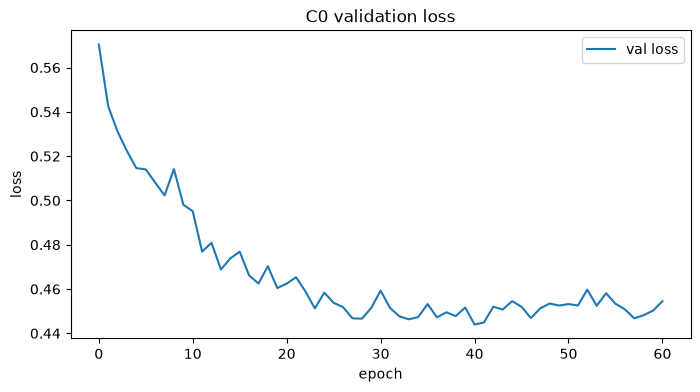

In [8]:
set_seed(SEED + 5000)
Xv, Yv = LabelledSampler(NAMES_VAL, SEED + 5000).batch(N_VAL)
C0_PATH = OUT / "models" / "model_C0.pth"

if C0_PATH.exists() and not RETRAIN:
    base = load_model(C0_PATH); print("loaded", C0_PATH)
else:
    t0 = time.time(); base = train_supervised(NAMES_TRAIN, Xv, Yv, RUN_SEED * 100)
    print(f"C0 trained in {(time.time()-t0)/60:.1f} min | {base.info}"); save_model(base, C0_PATH)
    plt.figure(figsize=(8, 4)); plt.plot(base.hist["val"], label="val loss"); plt.xlabel("epoch"); plt.ylabel("loss"); plt.legend()
    plt.title("C0 validation loss"); plt.savefig(OUT / "fig" / "C0_val_loss.png"); plt.show()



==================== C0 ====================


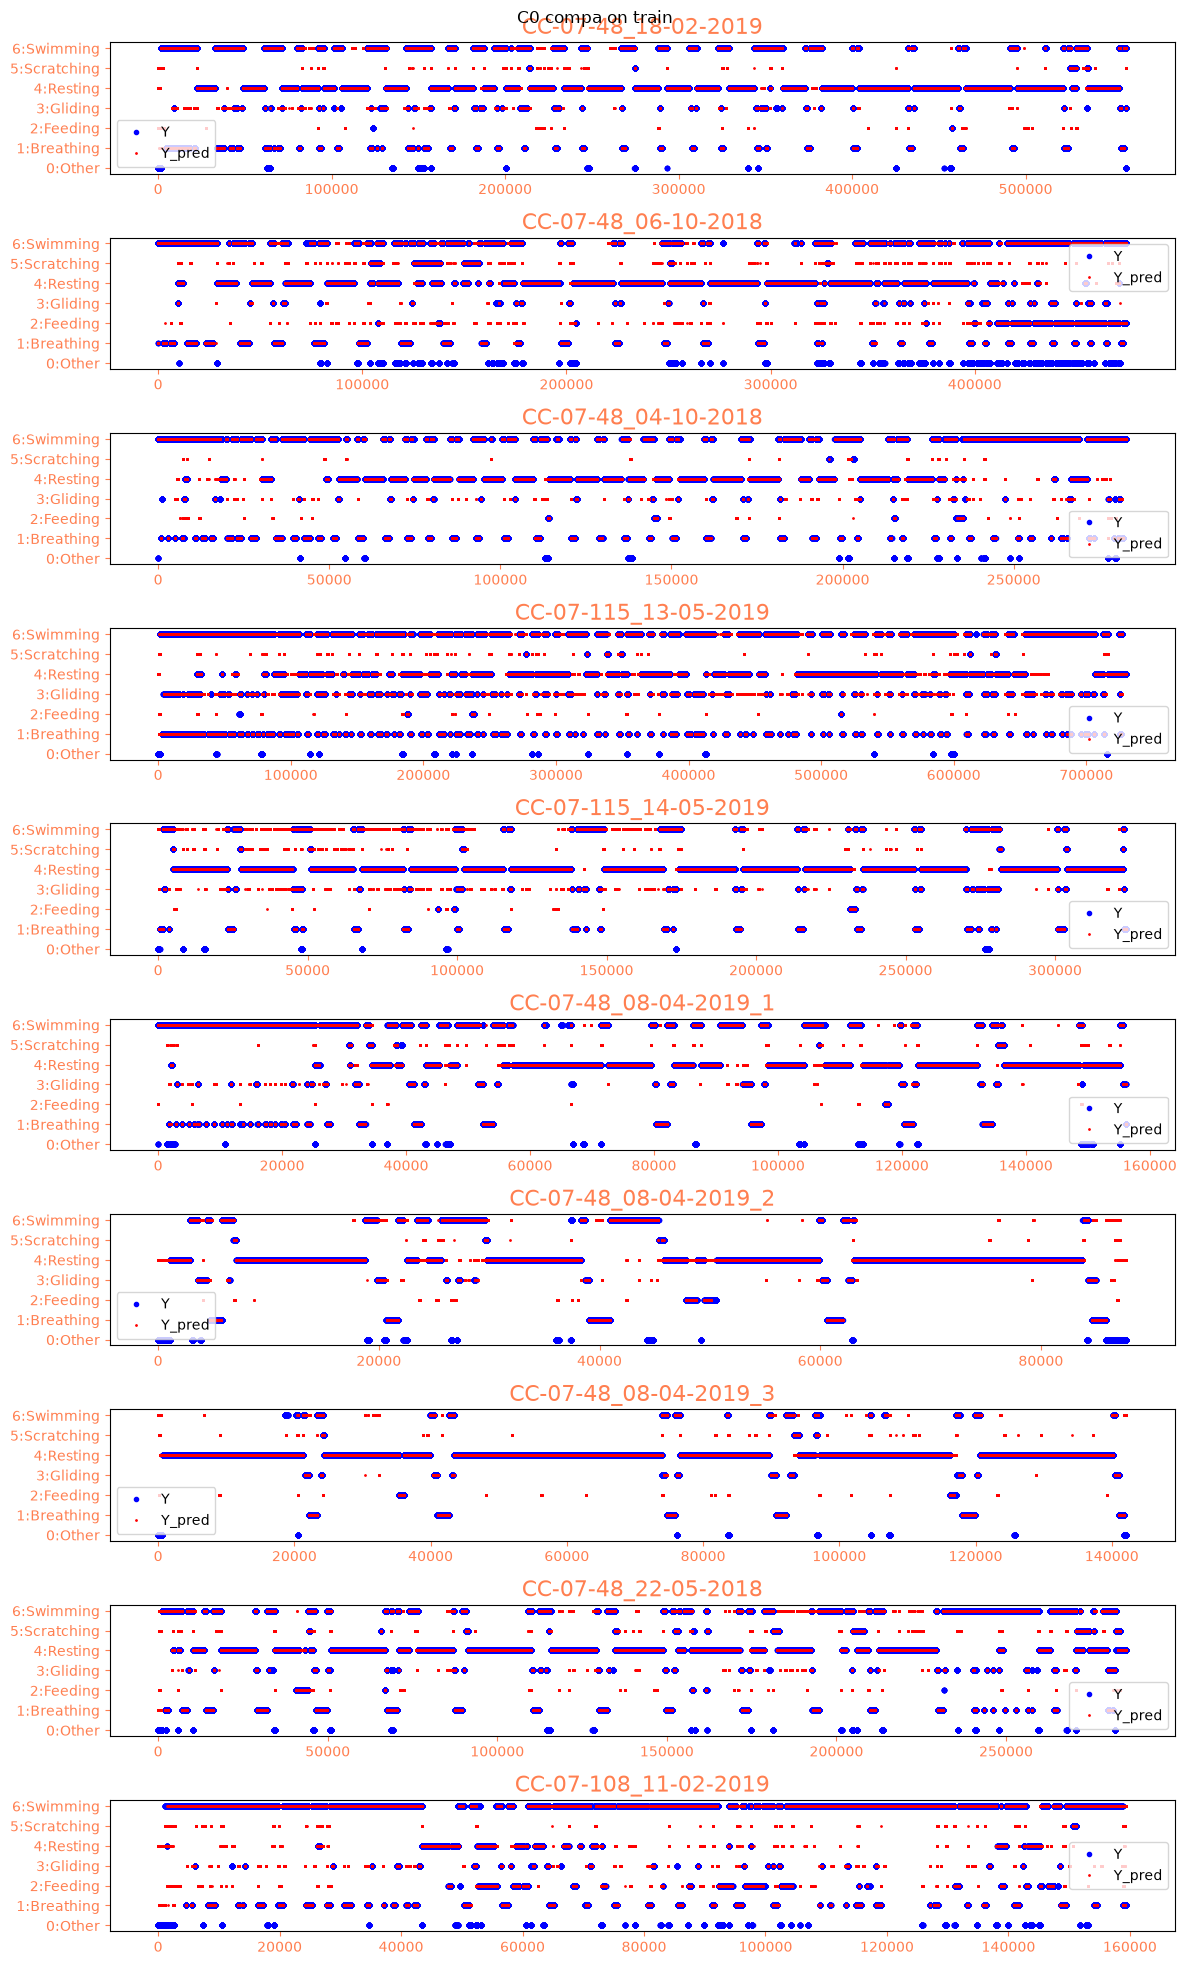

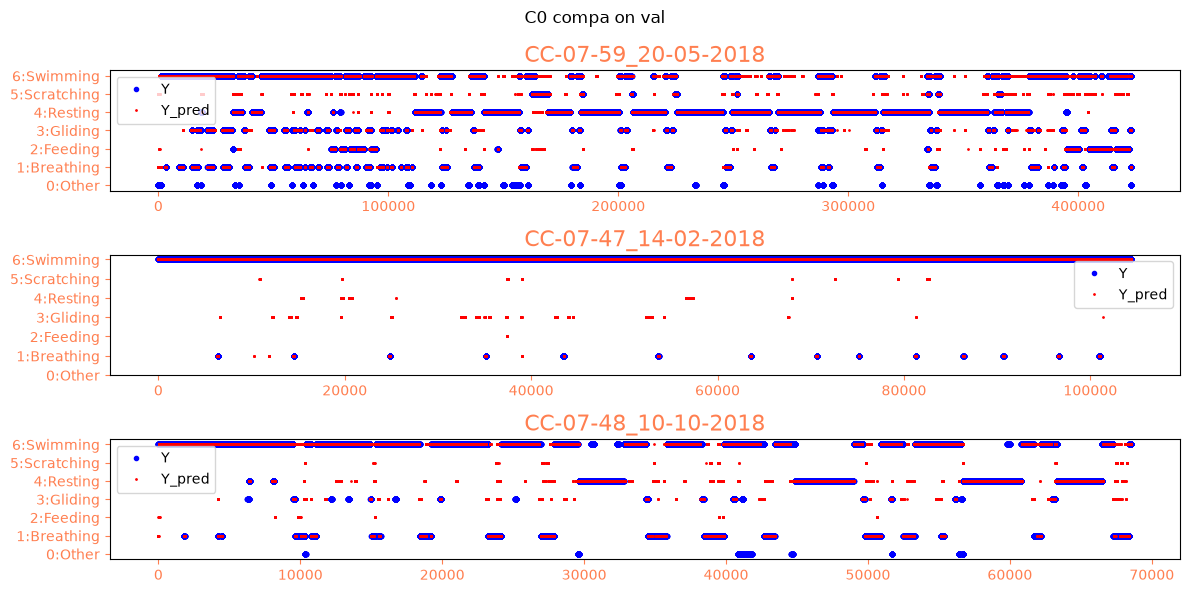

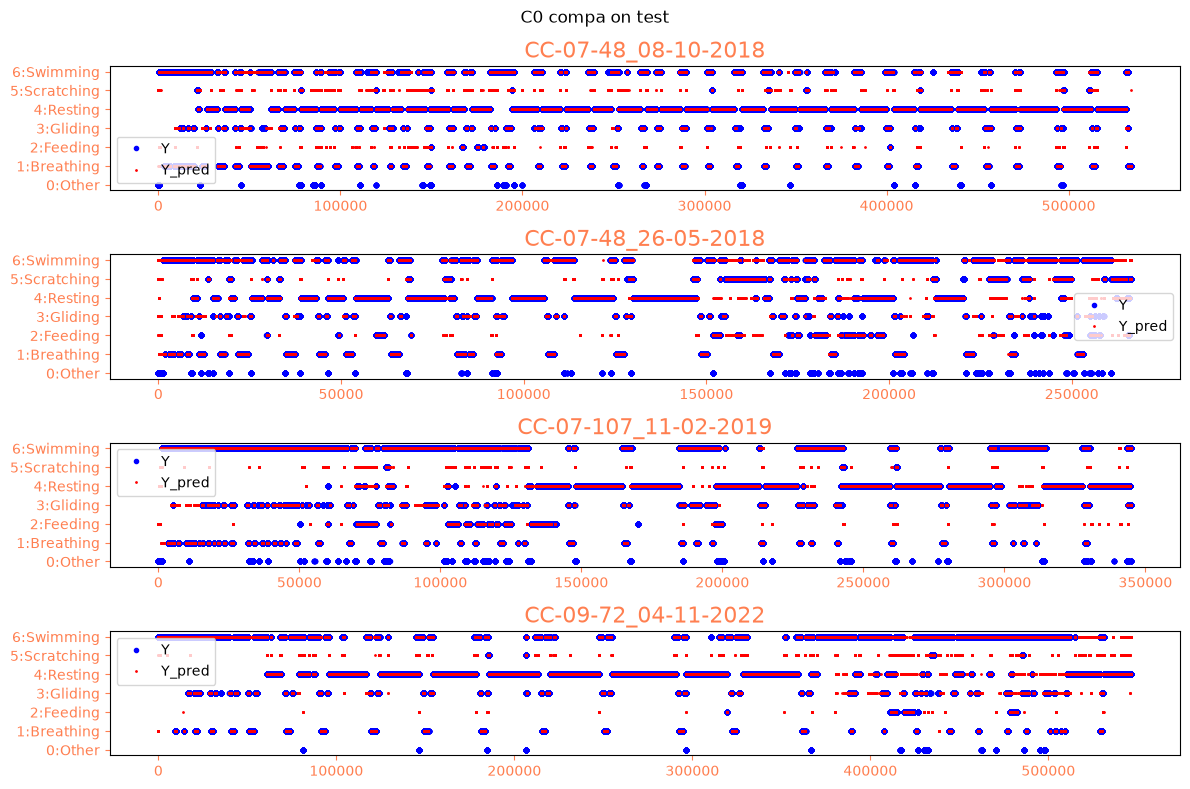


C0 | VAL | per-class (full-recording stitched predictions)
            Precision  Recall     F1  Support
Other             NaN   0.000  0.000     7447
Breathing       0.860   0.737  0.793    36219
Feeding         0.931   0.902  0.916    29990
Gliding         0.655   0.720  0.686    19288
Resting         0.966   0.950  0.958   216901
Scratching      0.360   0.624  0.457    10242
Swimming        0.906   0.932  0.919   275993
C0 | VAL | STITCHED (primary, same method as super.py) | avg F1 = 0.6757 | avg F1 (no Other) = 0.7883 | target F1 (Feeding/Scratching/Gliding) = 0.6863

C0 | TEST | per-class (full-recording stitched predictions)
            Precision  Recall     F1  Support
Other             NaN   0.000  0.000    18535
Breathing       0.958   0.900  0.928   145073
Feeding         0.722   0.625  0.670    43136
Gliding         0.814   0.776  0.795    92236
Resting         0.963   0.981  0.972   856777
Scratching      0.412   0.682  0.513    37356
Swimming        0.899   0.894  0.896 

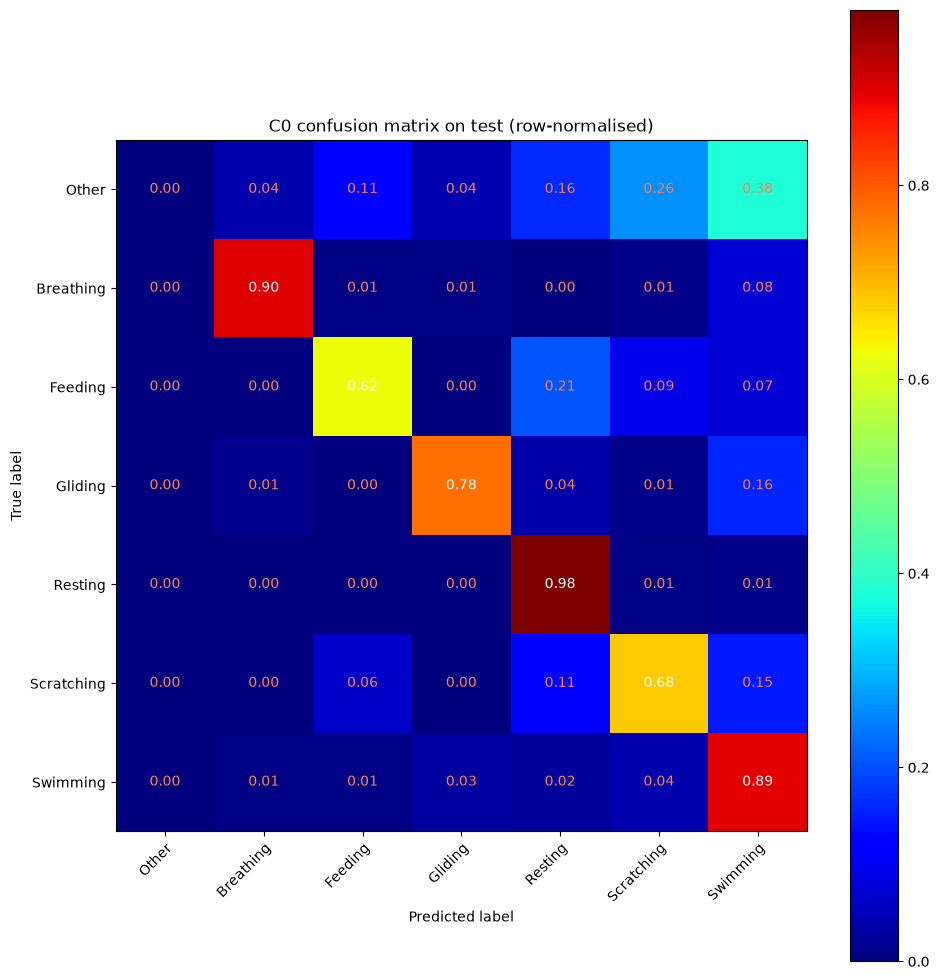

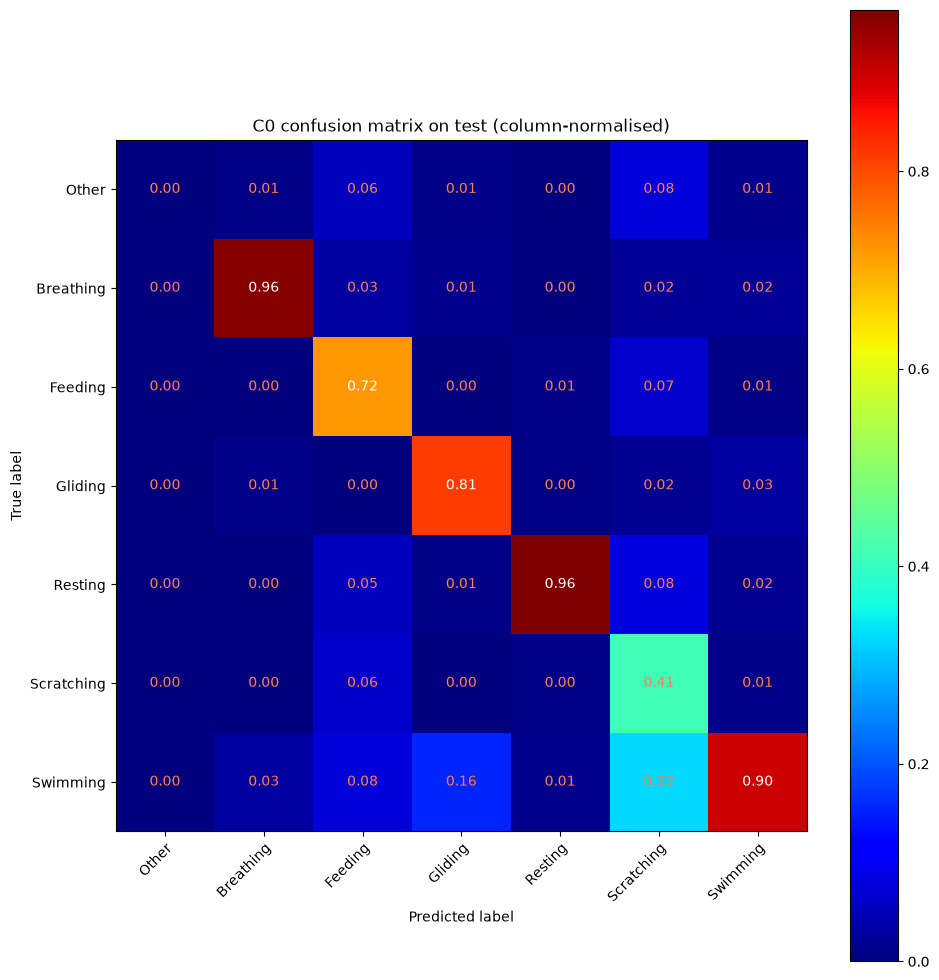

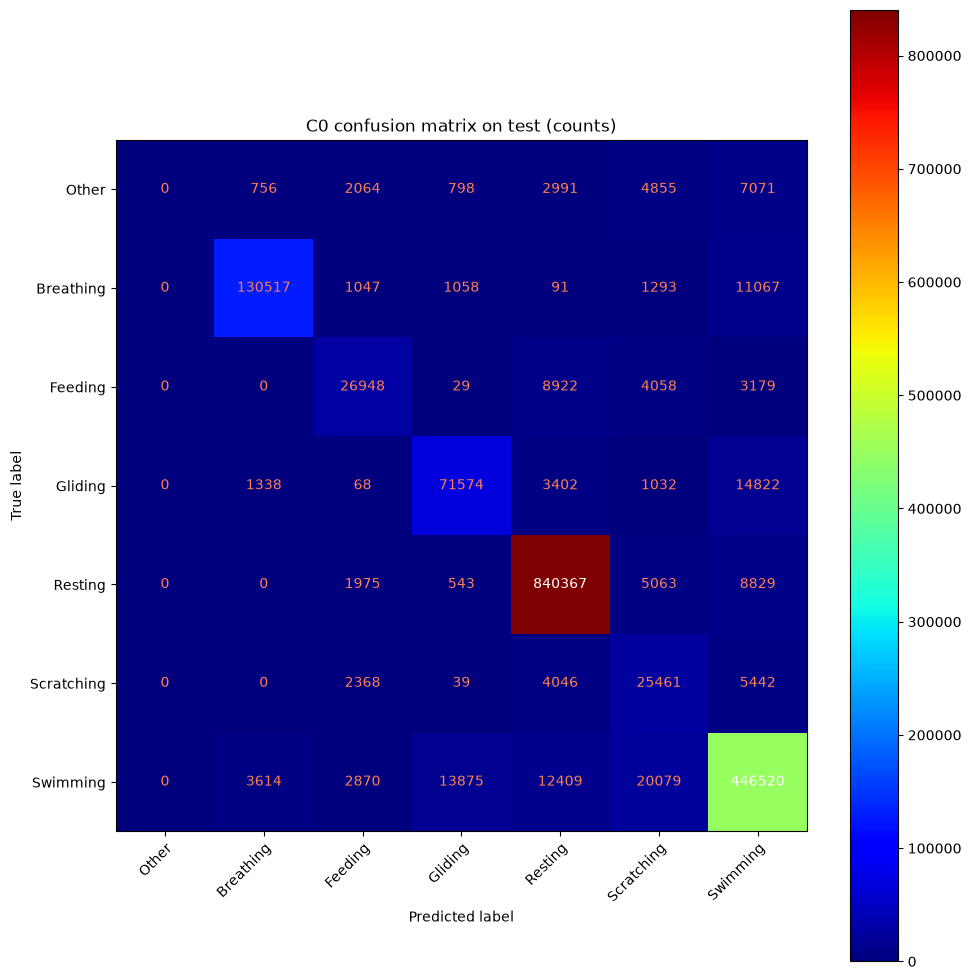

C0 | TEST non-overlapping windows (final.py method, edges included, expect lower) | avg F1 = 0.6779 | target F1 = 0.6525


In [9]:
report("C0", base)


 ## C2 with unlabelled pool A, B and AB

--- C2_A: round 1/3
{'pool': 'A', 'round': 1, 'n_candidates': 40000, 'n_keep': 30136, 'nwin_Other': 0, 'nwin_Breathing': 3165, 'nwin_Feeding': 2220, 'nwin_Gliding': 726, 'nwin_Resting': 18118, 'nwin_Scratching': 562, 'nwin_Swimming': 10458, 'n_selected': 4925, 'B_share_selected': 0.0}
saved: Model_results/FINAL_TRAIN_C0_C2_robust_2026_10_13/models/model_C2_A_round1.pth
--- C2_A: round 2/3
{'pool': 'A', 'round': 2, 'n_candidates': 40000, 'n_keep': 30819, 'nwin_Other': 0, 'nwin_Breathing': 4281, 'nwin_Feeding': 2390, 'nwin_Gliding': 790, 'nwin_Resting': 17488, 'nwin_Scratching': 501, 'nwin_Swimming': 11283, 'n_selected': 4939, 'B_share_selected': 0.0}
saved: Model_results/FINAL_TRAIN_C0_C2_robust_2026_10_13/models/model_C2_A_round2.pth
--- C2_A: round 3/3
{'pool': 'A', 'round': 3, 'n_candidates': 40000, 'n_keep': 32414, 'nwin_Other': 0, 'nwin_Breathing': 4492, 'nwin_Feeding': 2762, 'nwin_Gliding': 835, 'nwin_Resting': 18221, 'nwin_Scratching': 495, 'nwin_Swimming': 12482, 'n_selected': 4

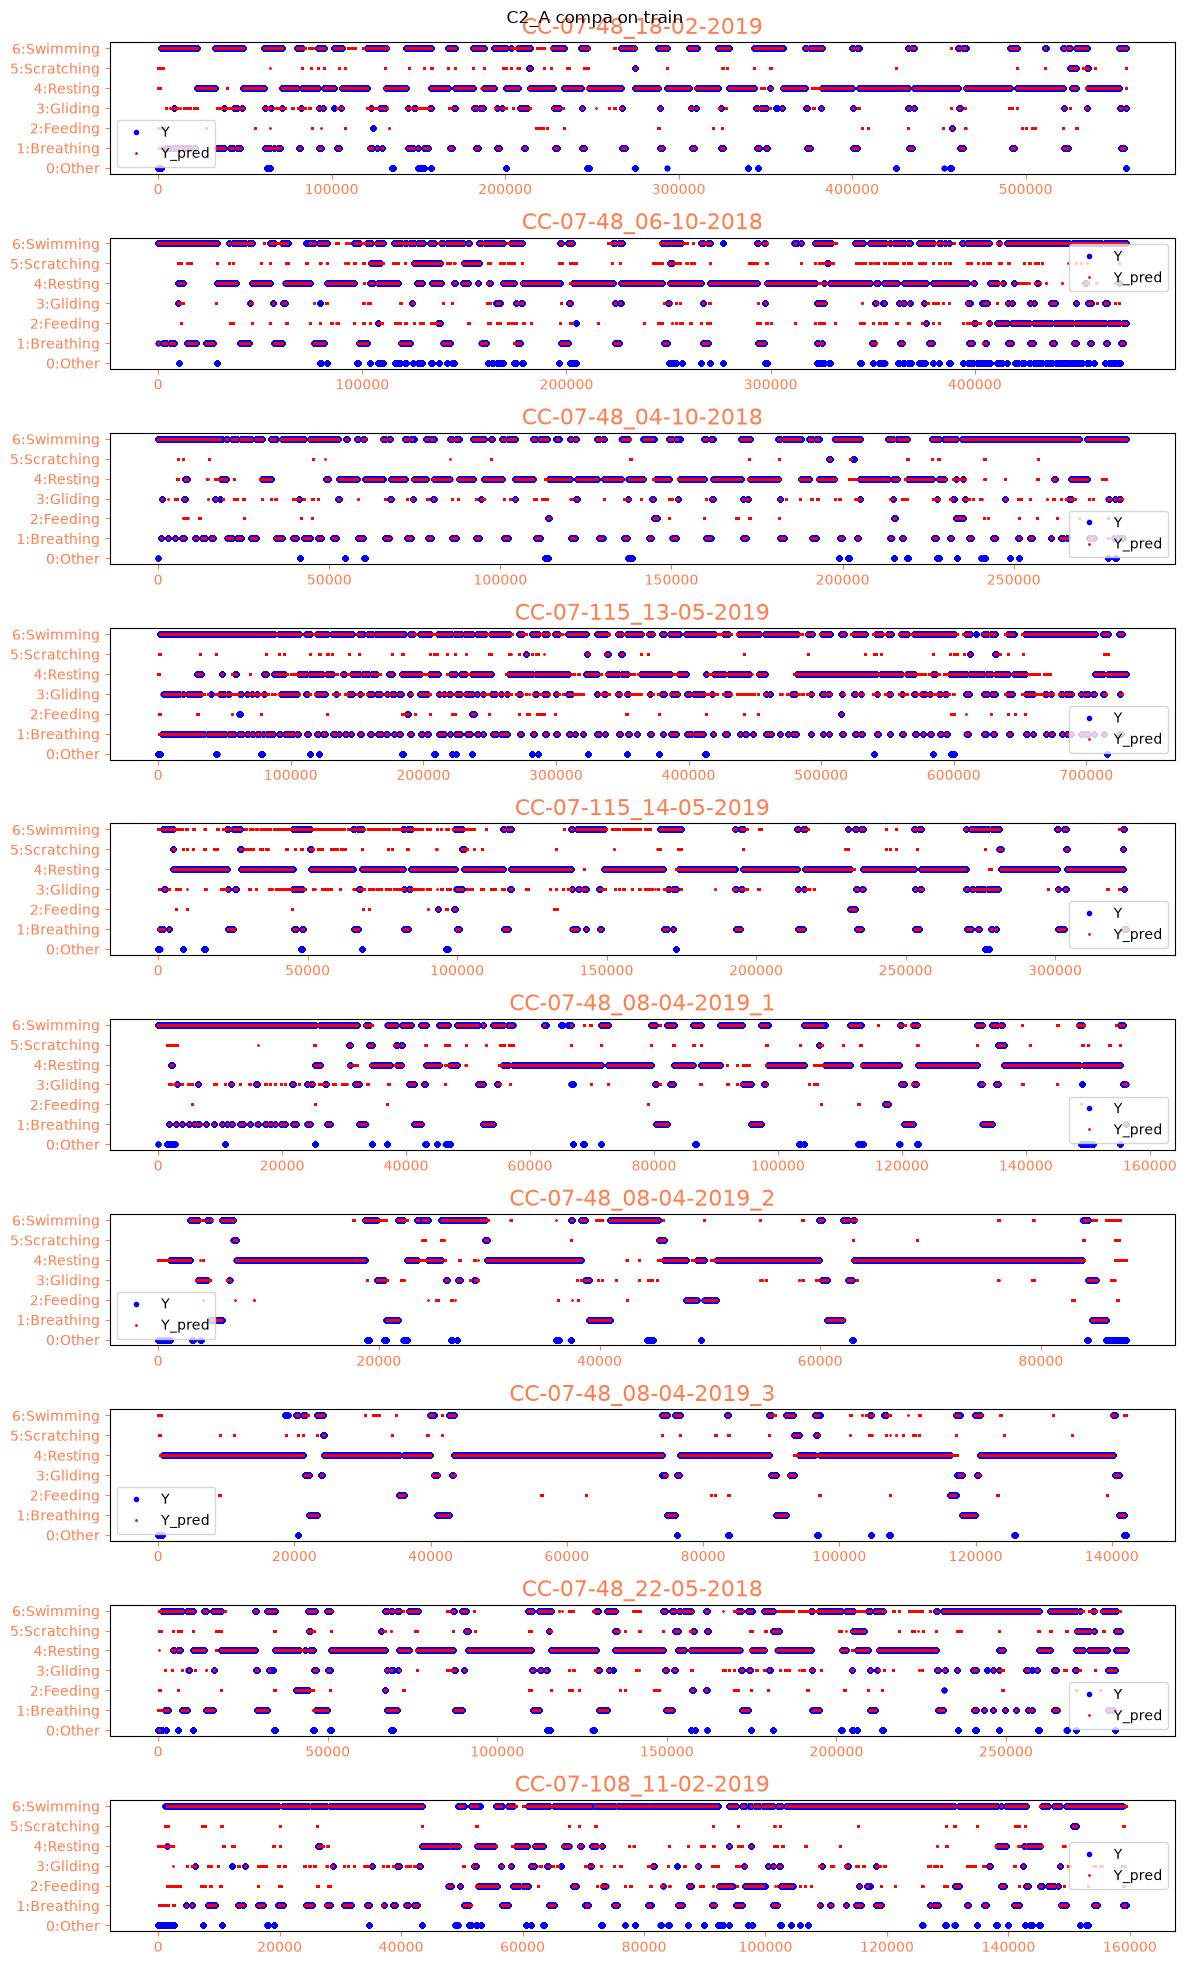

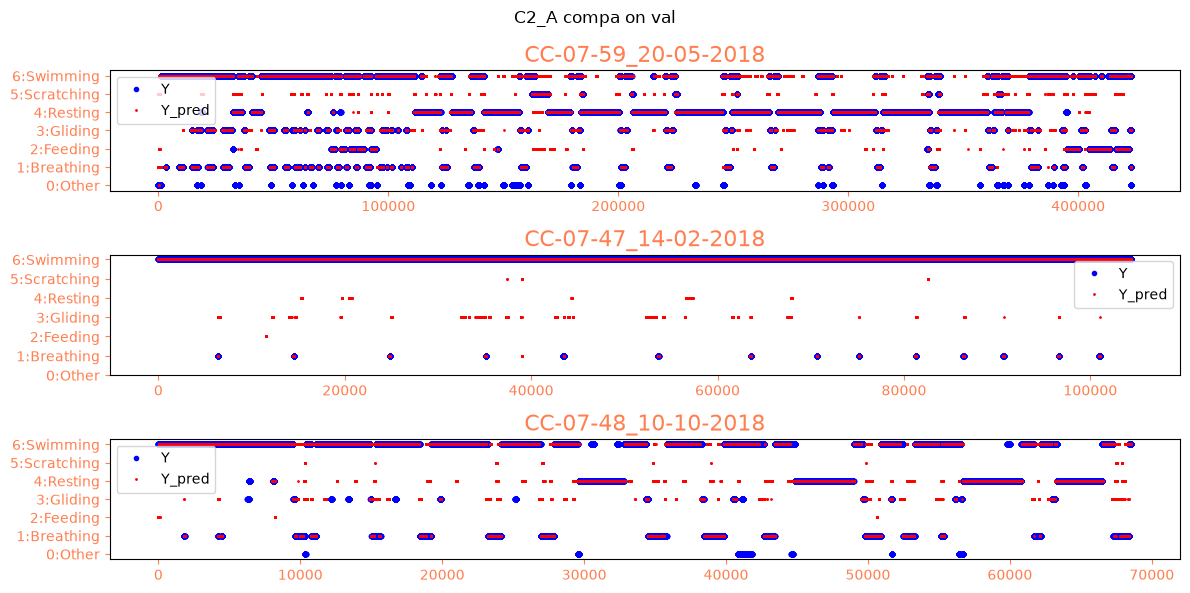

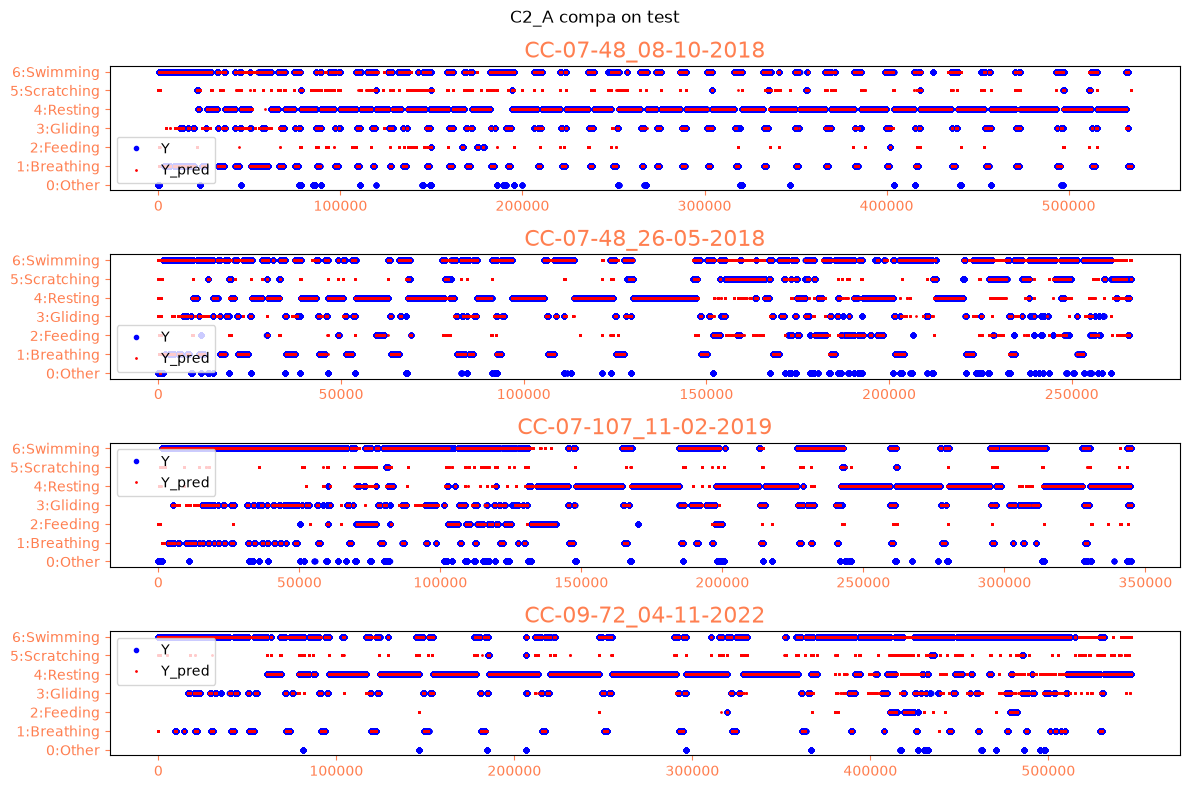


C2_A | VAL | per-class (full-recording stitched predictions)
            Precision  Recall     F1  Support
Other           1.000   0.000  0.001     7447
Breathing       0.893   0.710  0.791    36219
Feeding         0.924   0.917  0.920    29990
Gliding         0.579   0.773  0.662    19288
Resting         0.968   0.951  0.960   216901
Scratching      0.379   0.510  0.435    10242
Swimming        0.902   0.931  0.916   275993
C2_A | VAL | STITCHED (primary, same method as super.py) | avg F1 = 0.6693 | avg F1 (no Other) = 0.7807 | target F1 (Feeding/Scratching/Gliding) = 0.6726

C2_A | TEST | per-class (full-recording stitched predictions)
            Precision  Recall     F1  Support
Other           1.000   0.000  0.001    18535
Breathing       0.965   0.898  0.930   145073
Feeding         0.719   0.683  0.700    43136
Gliding         0.751   0.813  0.780    92236
Resting         0.965   0.981  0.973   856777
Scratching      0.415   0.578  0.483    37356
Swimming        0.896   0.887  

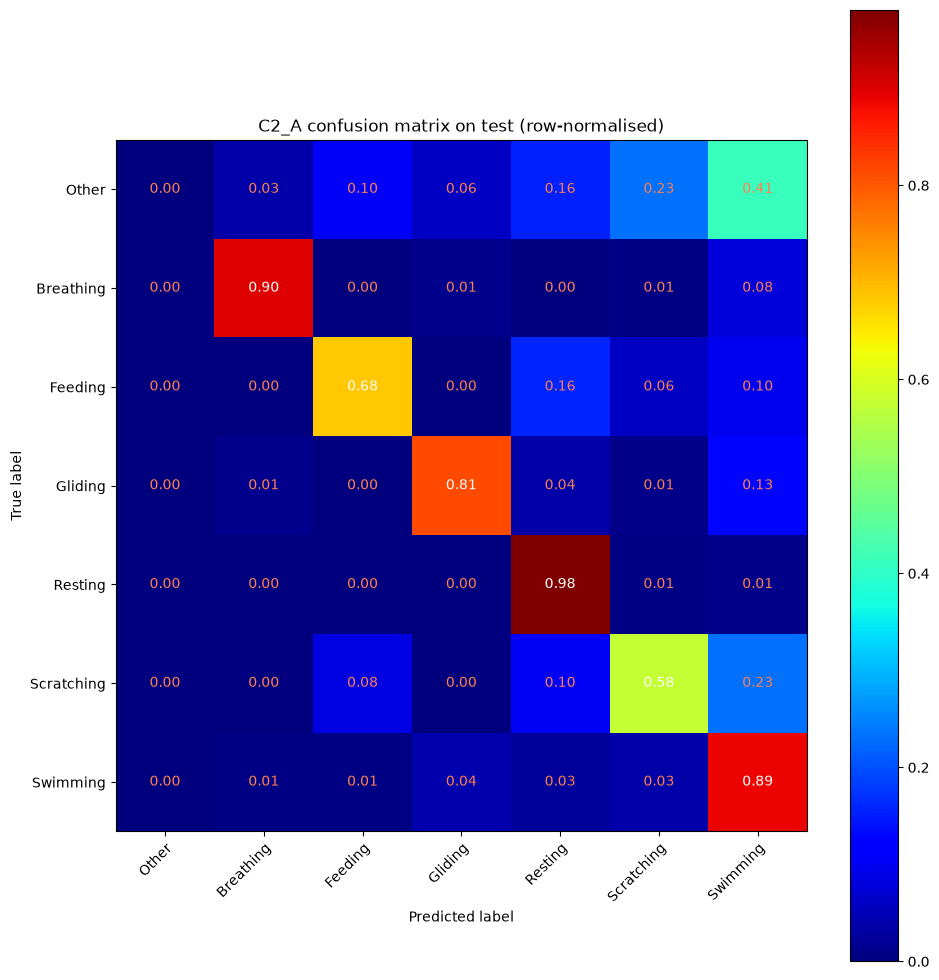

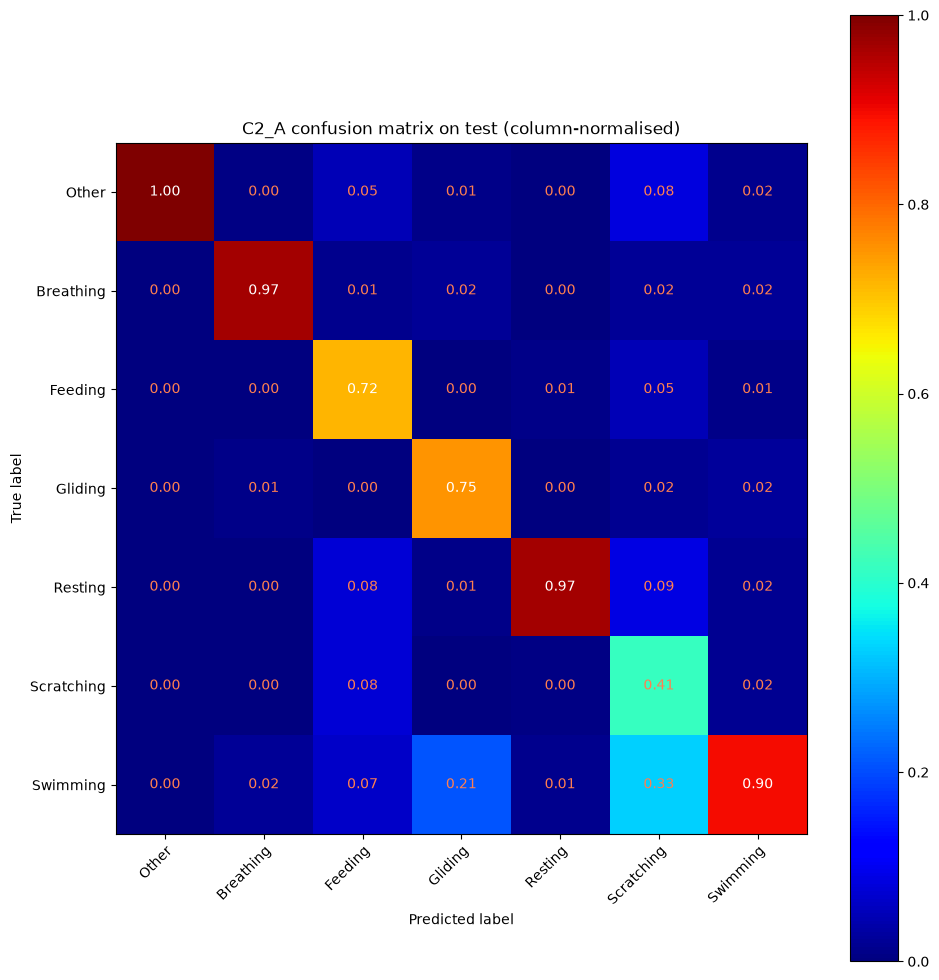

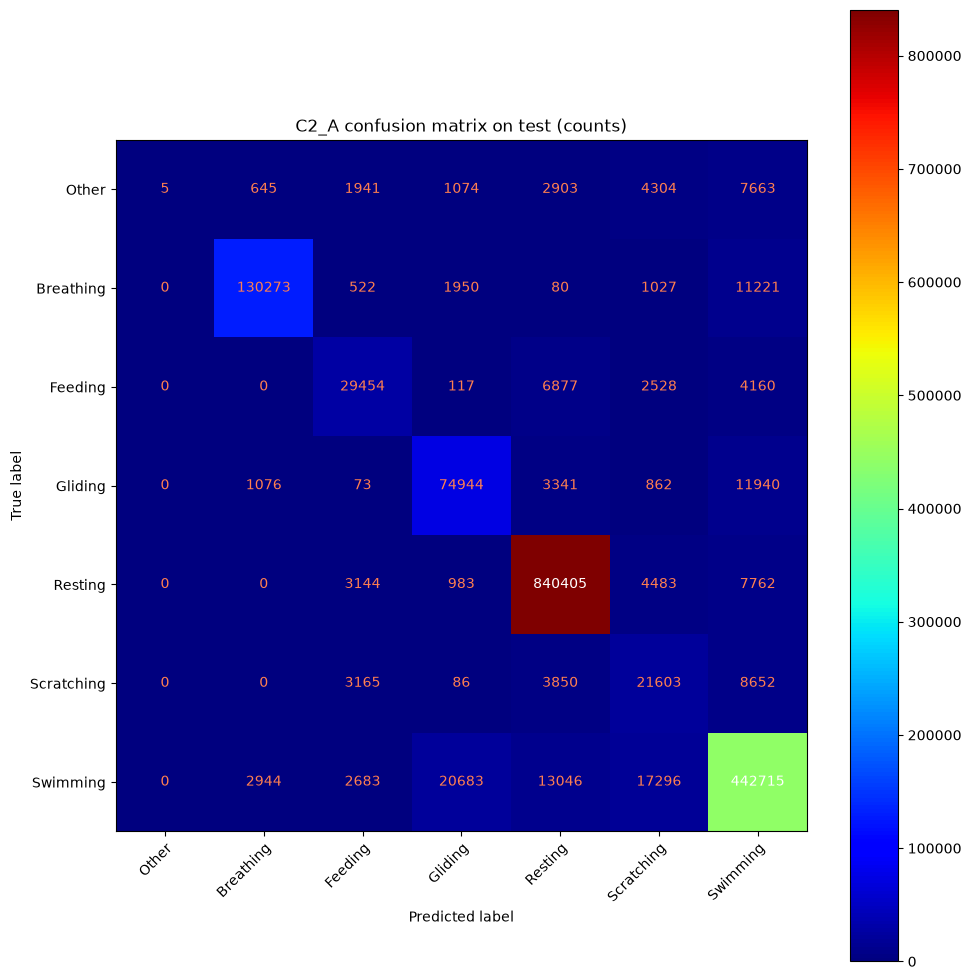

C2_A | TEST non-overlapping windows (final.py method, edges included, expect lower) | avg F1 = 0.6757 | target F1 = 0.6479
--- C2_B: round 1/3
{'pool': 'B', 'round': 1, 'n_candidates': 40000, 'n_keep': 27402, 'nwin_Other': 0, 'nwin_Breathing': 2742, 'nwin_Feeding': 4037, 'nwin_Gliding': 475, 'nwin_Resting': 16733, 'nwin_Scratching': 328, 'nwin_Swimming': 6902, 'n_selected': 4483, 'B_share_selected': 1.0}
saved: Model_results/FINAL_TRAIN_C0_C2_robust_2026_10_13/models/model_C2_B_round1.pth
--- C2_B: round 2/3
{'pool': 'B', 'round': 2, 'n_candidates': 40000, 'n_keep': 29141, 'nwin_Other': 0, 'nwin_Breathing': 2792, 'nwin_Feeding': 4408, 'nwin_Gliding': 214, 'nwin_Resting': 17229, 'nwin_Scratching': 363, 'nwin_Swimming': 8361, 'n_selected': 4354, 'B_share_selected': 1.0}
saved: Model_results/FINAL_TRAIN_C0_C2_robust_2026_10_13/models/model_C2_B_round2.pth
--- C2_B: round 3/3
{'pool': 'B', 'round': 3, 'n_candidates': 40000, 'n_keep': 27712, 'nwin_Other': 0, 'nwin_Breathing': 3068, 'nwin_Fe

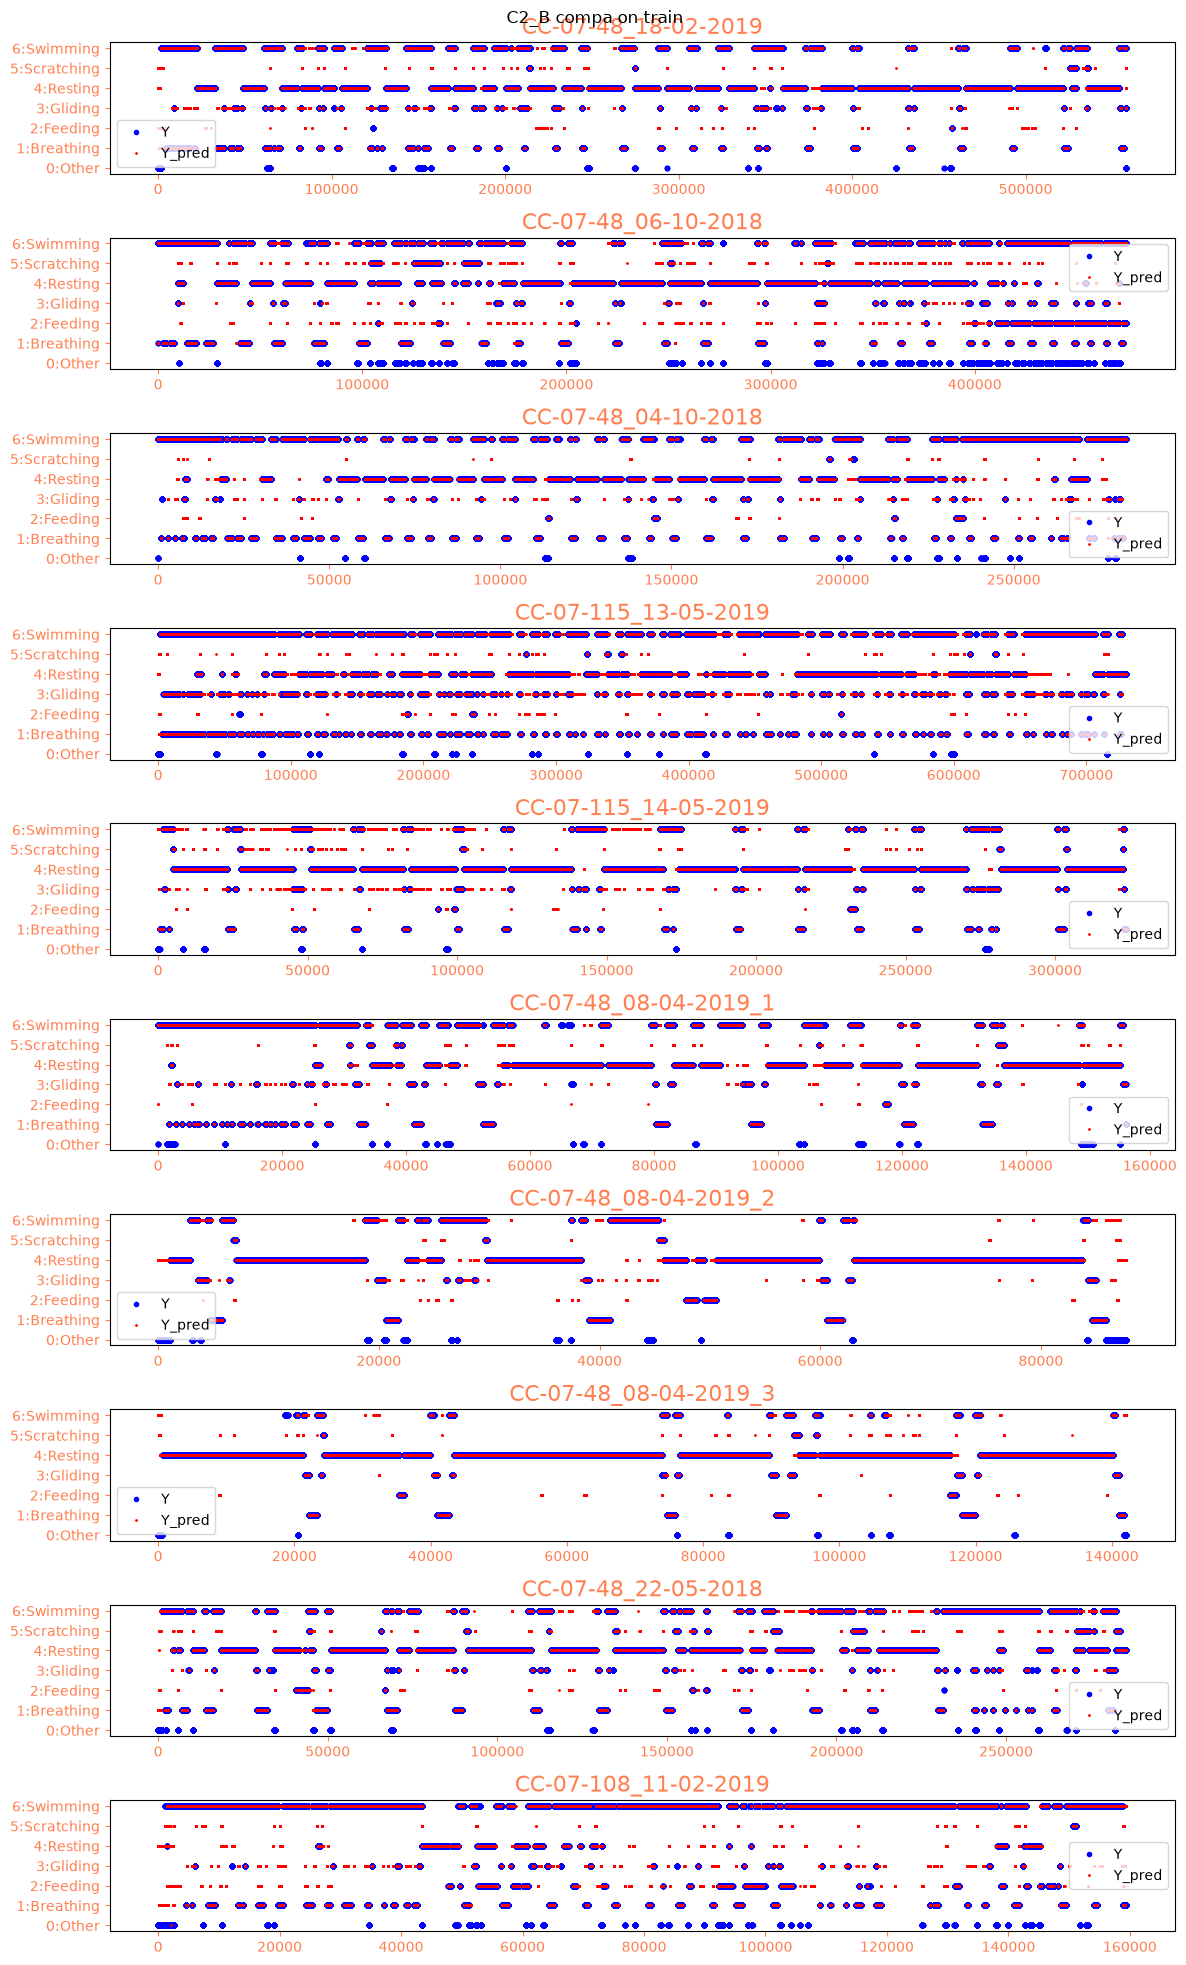

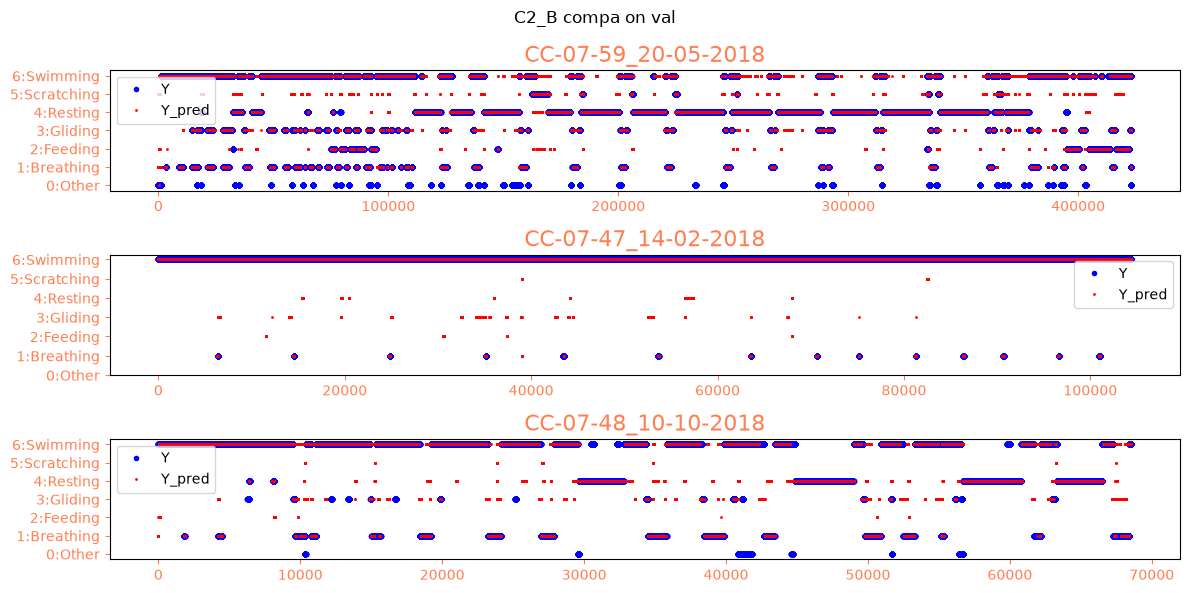

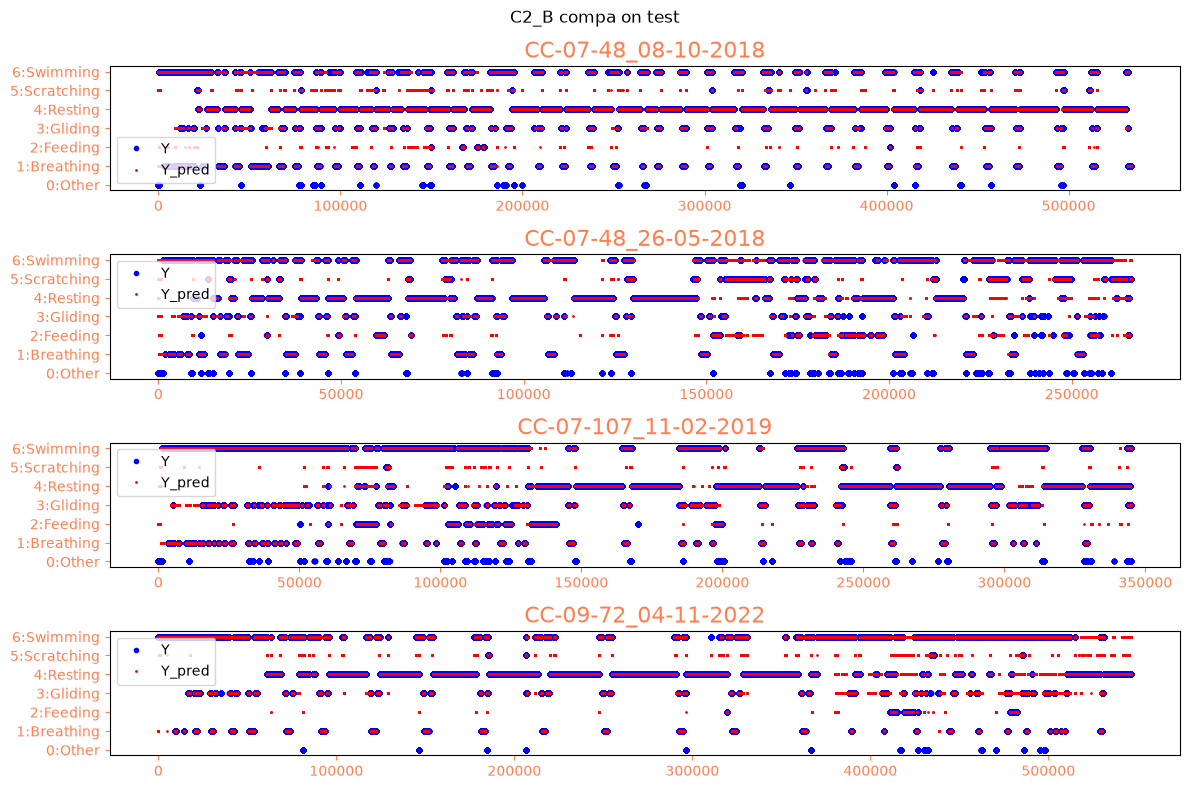


C2_B | VAL | per-class (full-recording stitched predictions)
            Precision  Recall     F1  Support
Other           1.000   0.000  0.001     7447
Breathing       0.862   0.742  0.797    36219
Feeding         0.927   0.913  0.920    29990
Gliding         0.605   0.743  0.667    19288
Resting         0.968   0.954  0.961   216901
Scratching      0.383   0.502  0.434    10242
Swimming        0.903   0.932  0.917   275993
C2_B | VAL | STITCHED (primary, same method as super.py) | avg F1 = 0.6711 | avg F1 (no Other) = 0.7828 | target F1 (Feeding/Scratching/Gliding) = 0.6737

C2_B | TEST | per-class (full-recording stitched predictions)
            Precision  Recall     F1  Support
Other             NaN   0.000  0.000    18535
Breathing       0.956   0.906  0.931   145073
Feeding         0.721   0.696  0.709    43136
Gliding         0.783   0.790  0.786    92236
Resting         0.966   0.983  0.974   856777
Scratching      0.451   0.604  0.516    37356
Swimming        0.897   0.895  

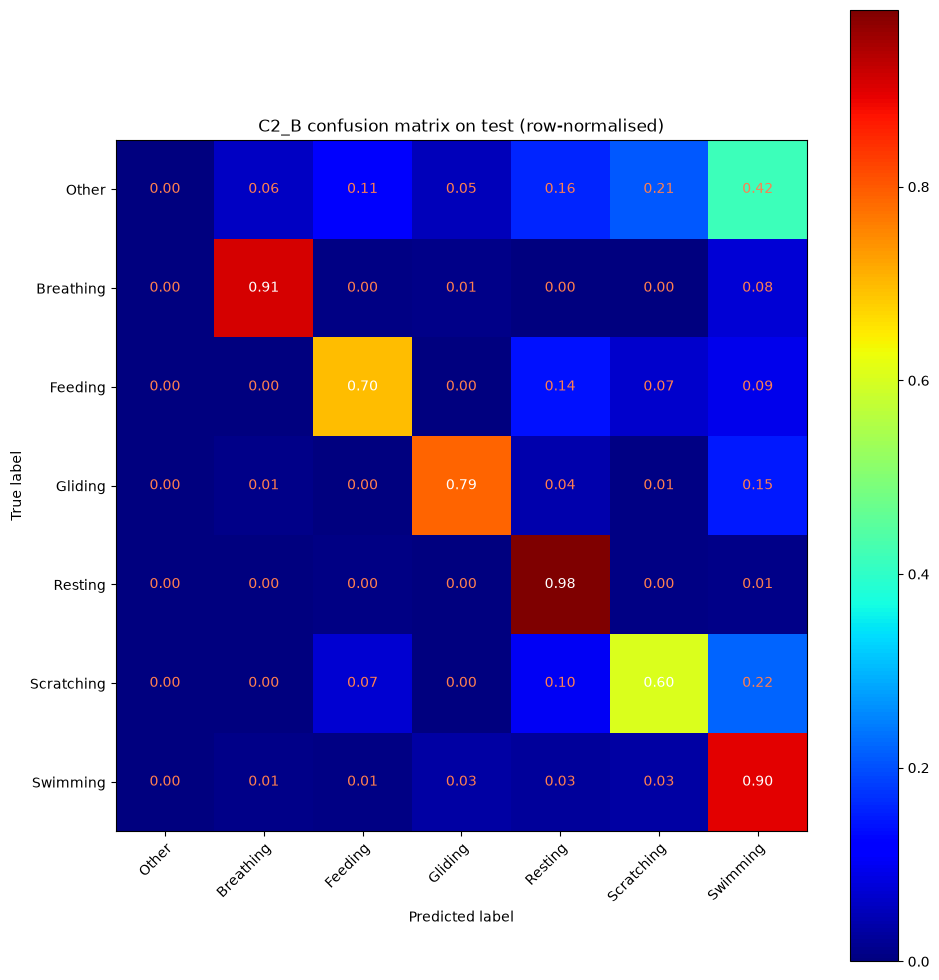

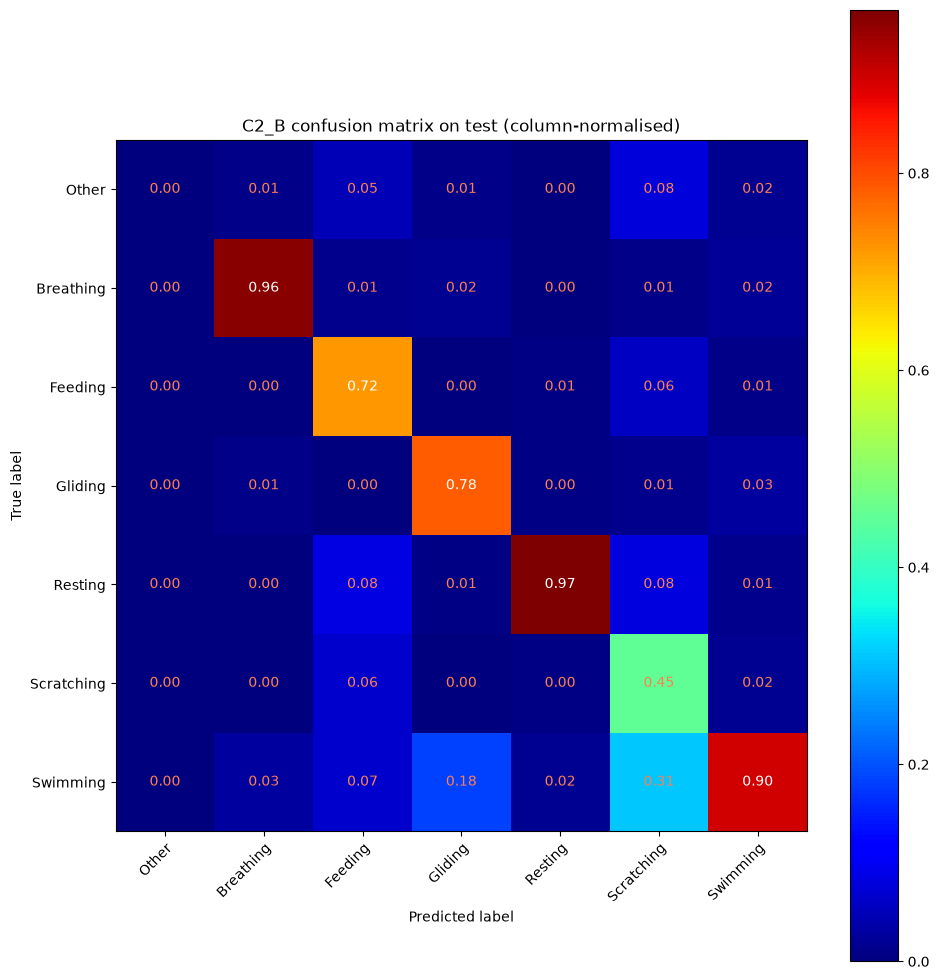

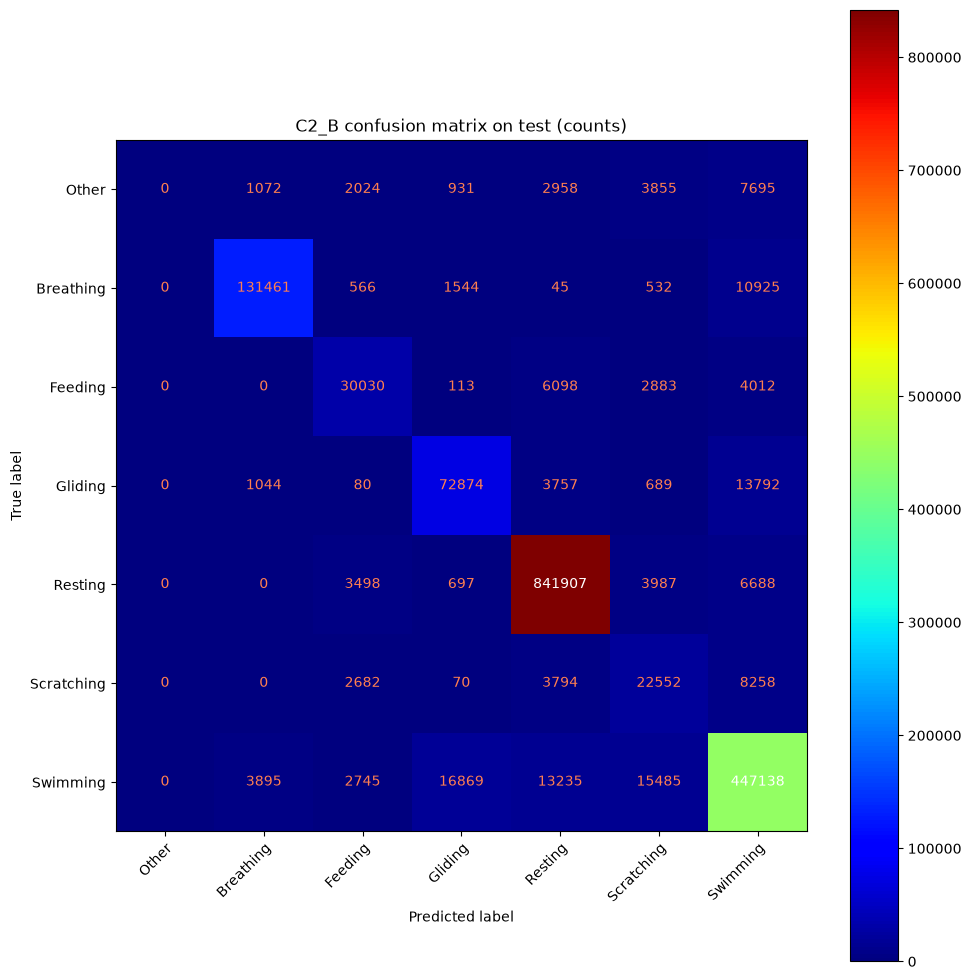

C2_B | TEST non-overlapping windows (final.py method, edges included, expect lower) | avg F1 = 0.6829 | target F1 = 0.6628
--- C2_AB: round 1/3
{'pool': 'AB', 'round': 1, 'n_candidates': 40000, 'n_keep': 27564, 'nwin_Other': 0, 'nwin_Breathing': 2863, 'nwin_Feeding': 3920, 'nwin_Gliding': 468, 'nwin_Resting': 16712, 'nwin_Scratching': 328, 'nwin_Swimming': 7246, 'n_selected': 4476, 'B_share_selected': 0.8916443252904379}
saved: Model_results/FINAL_TRAIN_C0_C2_robust_2026_10_13/models/model_C2_AB_round1.pth
--- C2_AB: round 2/3
{'pool': 'AB', 'round': 2, 'n_candidates': 40000, 'n_keep': 26997, 'nwin_Other': 0, 'nwin_Breathing': 3046, 'nwin_Feeding': 4117, 'nwin_Gliding': 0, 'nwin_Resting': 16484, 'nwin_Scratching': 215, 'nwin_Swimming': 6870, 'n_selected': 4022, 'B_share_selected': 0.9015415216310293}
saved: Model_results/FINAL_TRAIN_C0_C2_robust_2026_10_13/models/model_C2_AB_round2.pth
--- C2_AB: round 3/3
{'pool': 'AB', 'round': 3, 'n_candidates': 40000, 'n_keep': 28796, 'nwin_Other':

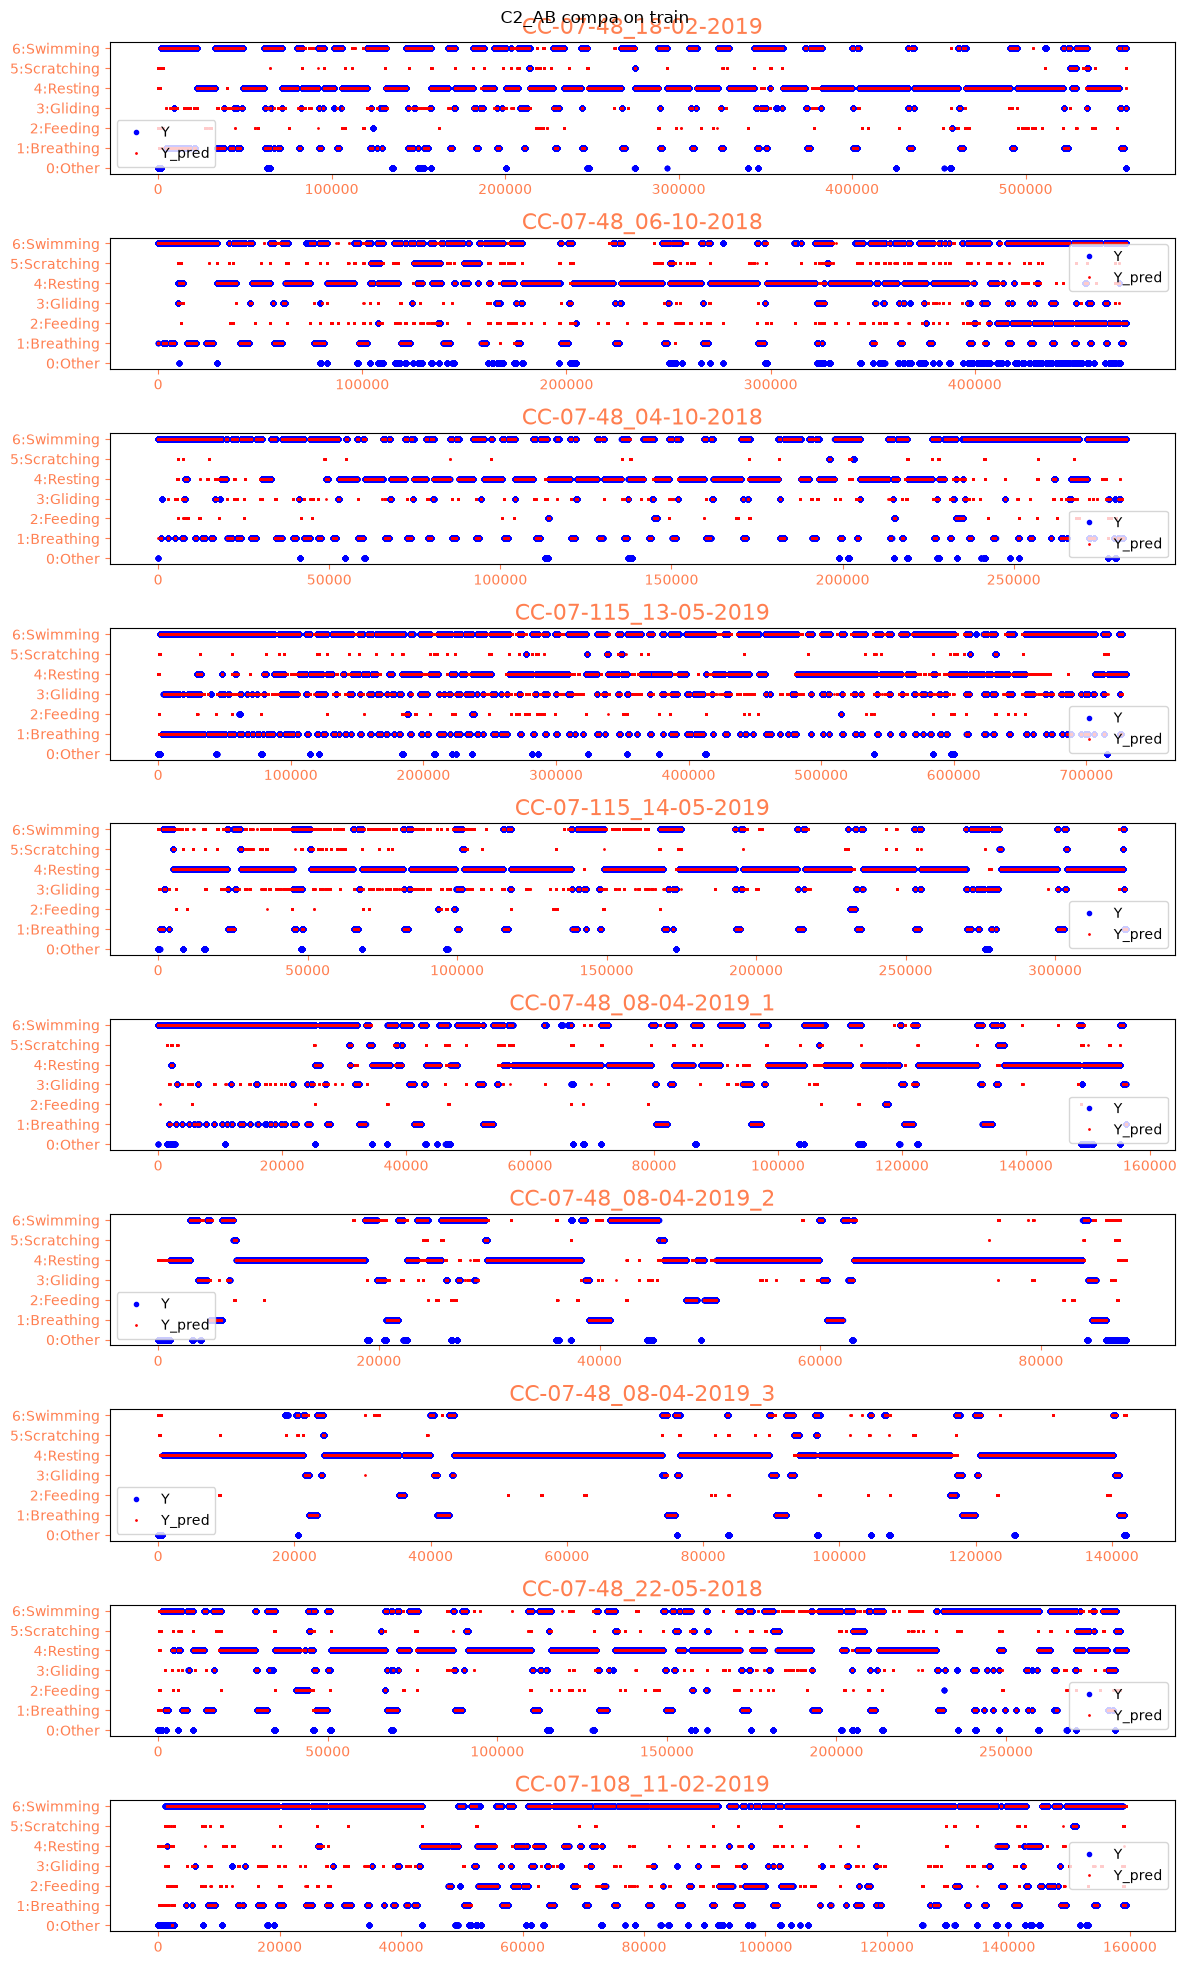

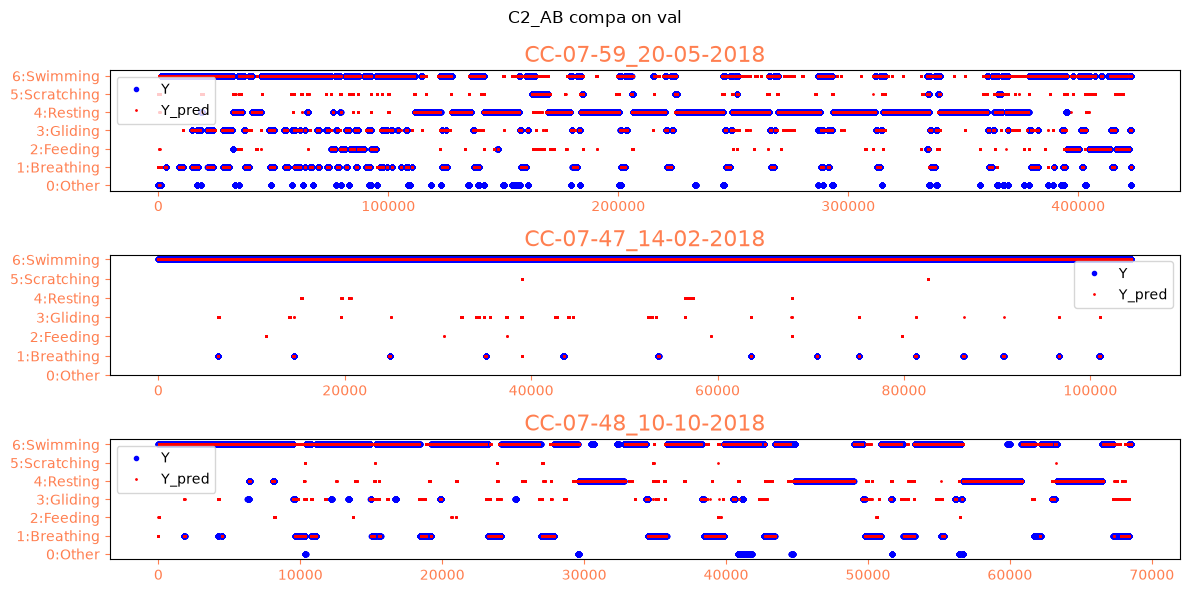

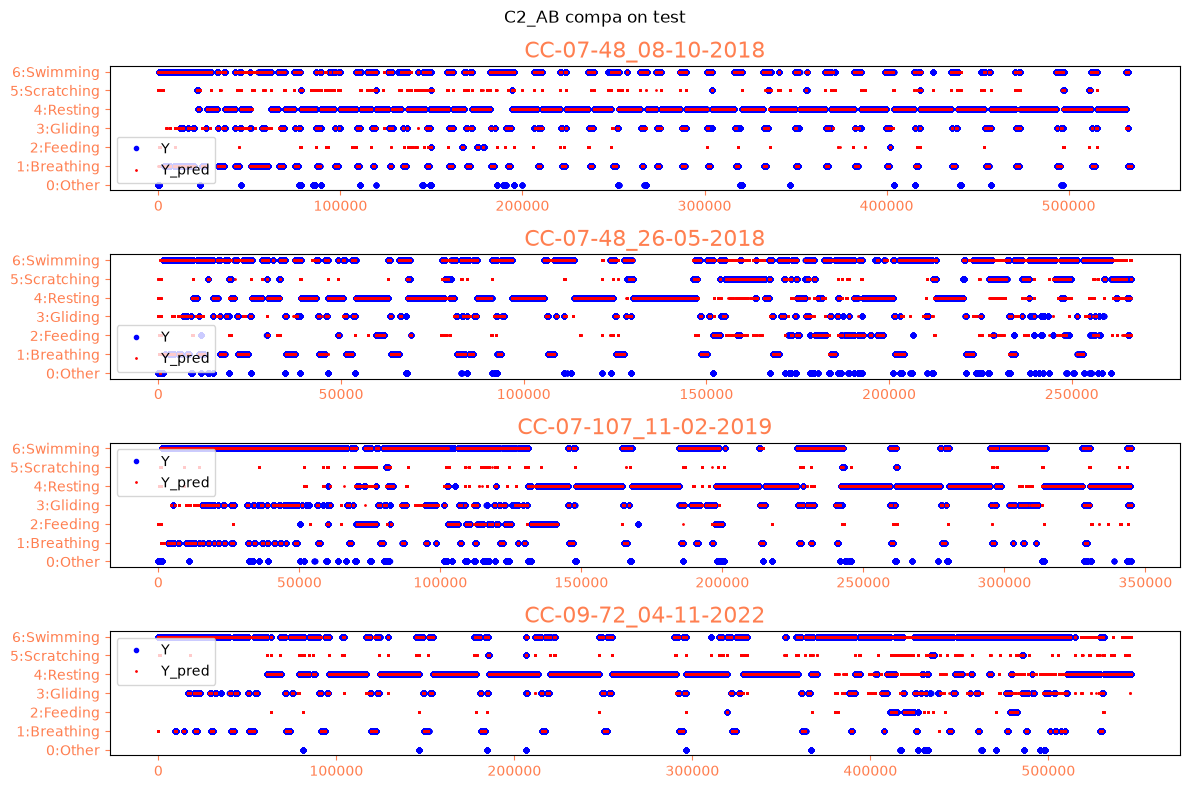


C2_AB | VAL | per-class (full-recording stitched predictions)
            Precision  Recall     F1  Support
Other           1.000   0.001  0.002     7447
Breathing       0.886   0.692  0.777    36219
Feeding         0.902   0.928  0.915    29990
Gliding         0.620   0.726  0.669    19288
Resting         0.967   0.952  0.960   216901
Scratching      0.394   0.510  0.445    10242
Swimming        0.903   0.940  0.921   275993
C2_AB | VAL | STITCHED (primary, same method as super.py) | avg F1 = 0.6696 | avg F1 (no Other) = 0.7810 | target F1 (Feeding/Scratching/Gliding) = 0.6761

C2_AB | TEST | per-class (full-recording stitched predictions)
            Precision  Recall     F1  Support
Other           1.000   0.000  0.000    18535
Breathing       0.961   0.901  0.930   145073
Feeding         0.686   0.724  0.704    43136
Gliding         0.804   0.771  0.787    92236
Resting         0.964   0.983  0.973   856777
Scratching      0.445   0.577  0.502    37356
Swimming        0.895   0.89

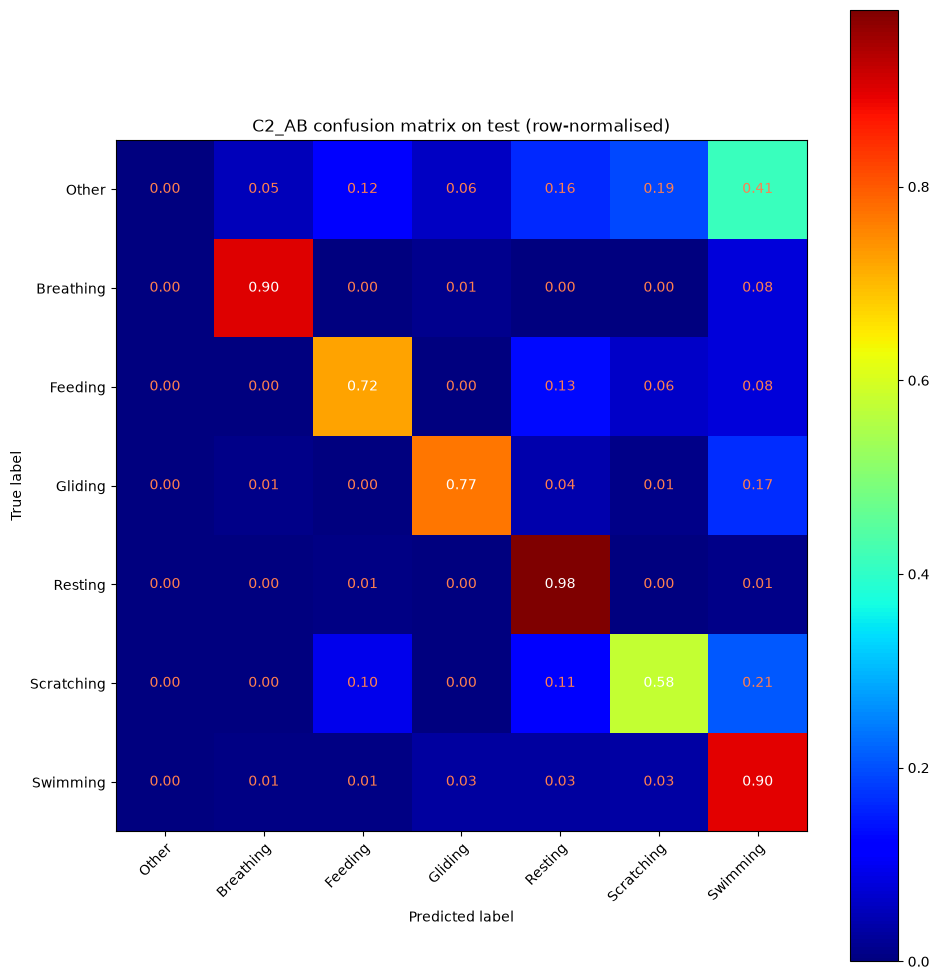

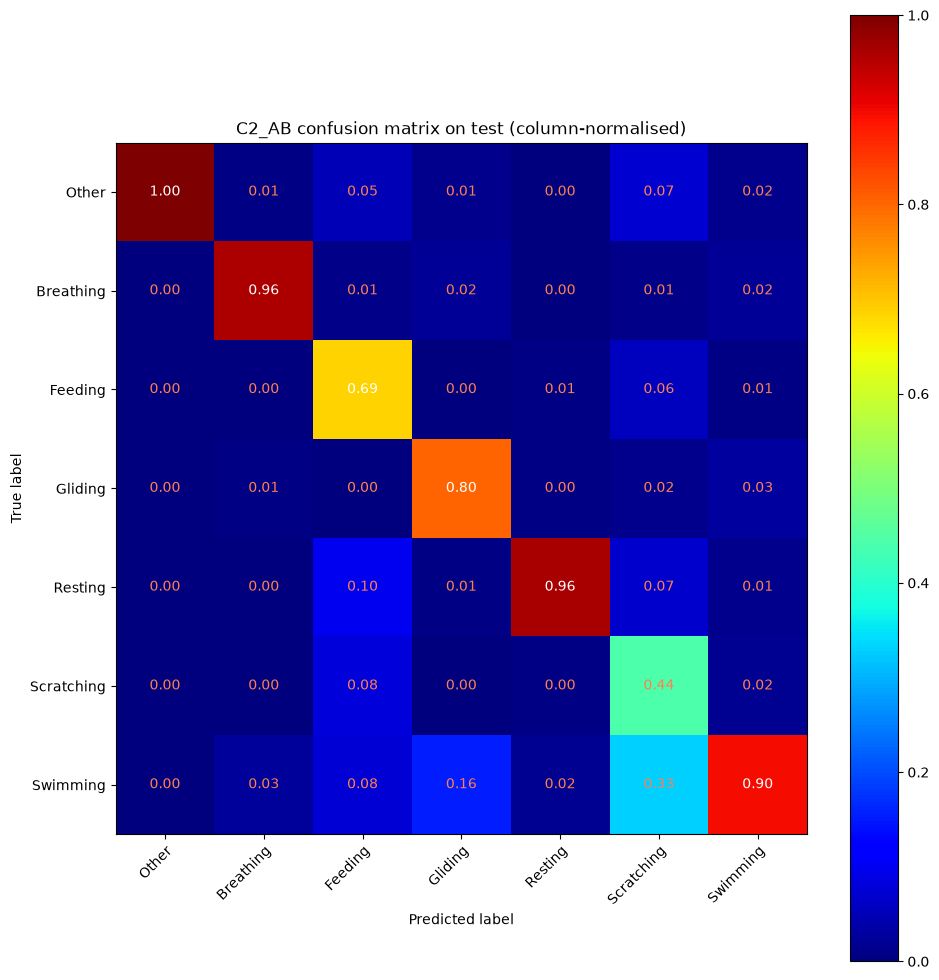

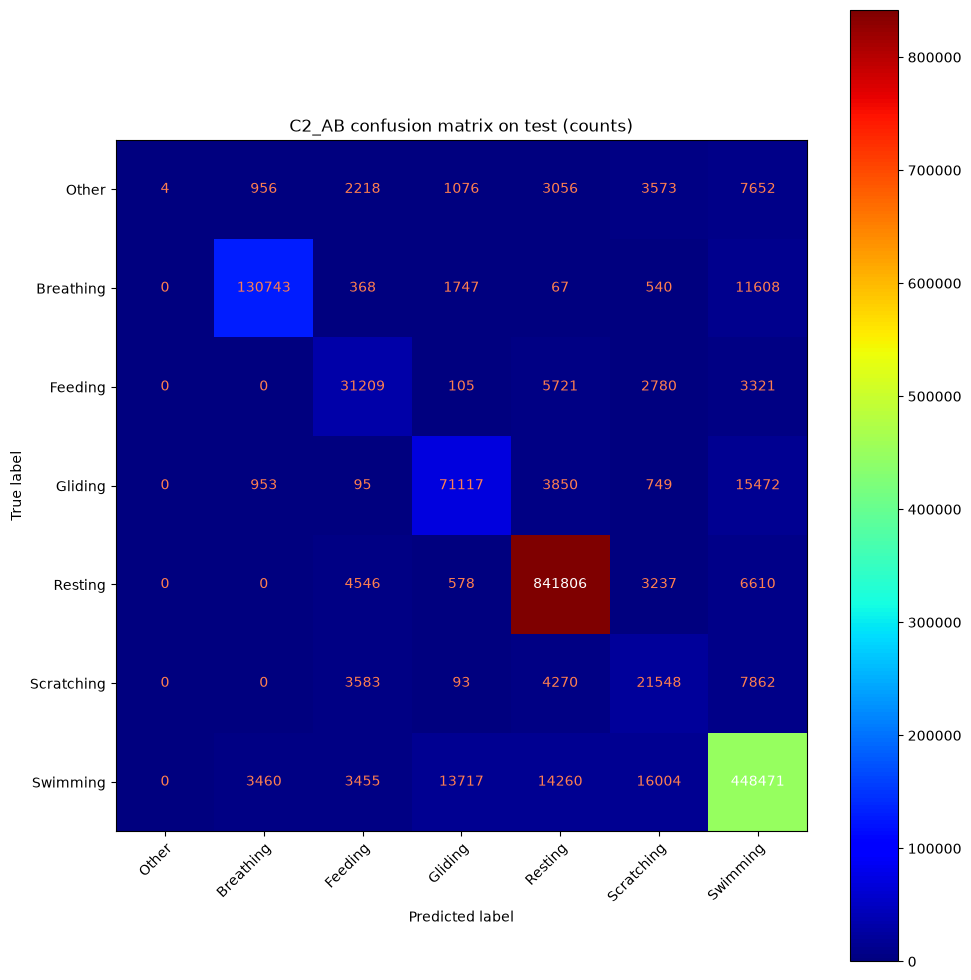

C2_AB | TEST non-overlapping windows (final.py method, edges included, expect lower) | avg F1 = 0.6803 | target F1 = 0.6568


In [10]:
C2_MODELS = {}
for pool in POOLS:
    tag = f"C2_{pool}"; path = OUT / "models" / f"model_{tag}.pth"
    if path.exists() and not RETRAIN:
        m = load_model(path); print("loaded", path)
    else:
        m = run_c2(list(pool) if pool != "AB" else ["A", "B"], base); save_model(m, path)
    C2_MODELS[tag] = m
    report(tag, m)


 ## Summary

In [11]:
summary = pd.DataFrame(RESULTS).set_index("model")
cols = ["test_avg_F1", "test_avg_F1_noOther", "test_target_F1", "test_windows_avg_F1", "test_windows_target_F1", "val_avg_F1"] + [f"test_F1_{c}" for c in CLASS_NAMES]
display(summary[cols].round(4)) if "display" in globals() else print(summary[cols].round(4))
summary.to_csv(OUT / "summary_all_models.csv")
print("models saved in", OUT / "models", "- reload with load_model(path)")


       test_avg_F1  test_avg_F1_noOther  test_target_F1  test_windows_avg_F1  test_windows_target_F1  val_avg_F1  test_F1_Other  test_F1_Breathing  test_F1_Feeding  test_F1_Gliding  test_F1_Resting  test_F1_Scratching  \
model                                                                                                                                                                                                                       
C0          0.6820               0.7957          0.6592               0.6779                  0.6525      0.6757         0.0000             0.9280           0.6697           0.7946           0.9721              0.5133   
C2_A        0.6799               0.7931          0.6545               0.6757                  0.6479      0.6693         0.0005             0.9305           0.7003           0.7804           0.9731              0.4830   
C2_B        0.6875               0.8020          0.6705               0.6829                  0.6628      0.6711    

## Export stitched predictions for all final models

This uses the same 40 s overlapping windows and 10% edge trimming as the evaluation above. Each model is written to its own directory so predictions are not overwritten.

In [ ]:
# `get_all` above implements the same cut_full_slice/stick logic as C=predictions_Vnet_GT.
# Export C0 and all final C2 variants on the labelled recordings in NAMES_ALL.
PREDICTION_MODELS = {"C0": base, **C2_MODELS}
PRED_OUT = OUT / "predictions"
PRED_OUT.mkdir(parents=True, exist_ok=True)

all_predictions = {}
prediction_rows = []
for tag, model in PREDICTION_MODELS.items():
    model_out = PRED_OUT / tag
    model_out.mkdir(parents=True, exist_ok=True)
    predictions, truths = get_all(model, NAMES_ALL, bs=64)
    all_predictions[tag] = predictions

    for name, y_pred in predictions.items():
        np.save(model_out / f"{name}=Y_pred.npy", y_pred.astype(np.int8))
        pd.DataFrame({
            "sample": np.arange(len(y_pred)),
            "prediction": y_pred.astype(np.int8),
            "true_label": truths[name].astype(np.int8),
        }).to_csv(model_out / f"{name}=Y_pred.csv", index=False)
        prediction_rows.append(pd.DataFrame({
            "model": tag,
            "recording": name,
            "sample": np.arange(len(y_pred)),
            "prediction": y_pred.astype(np.int8),
            "true_label": truths[name].astype(np.int8),
        }))

predictions_long = pd.concat(prediction_rows, ignore_index=True)
predictions_long.to_csv(PRED_OUT / "all_predictions.csv", index=False)
print(f"Saved predictions for {len(PREDICTION_MODELS)} models and {len(NAMES_ALL)} recordings in {PRED_OUT}")
